# TT2 · Detección y Mitigación de Calibration Drift — Polish Companies Bankruptcy
**Trabajo Terminal 2026-B080 · ESCOM-IPN** · Casas Aguilar José David · Robles Cervantes Pedro Iván

Notebook final de código (fase TT2) para el dataset *Polish Companies Bankruptcy* (UCI 365). Se ejecuta de punta a punta en Google Colab y deja exportados el modelo, el pipeline de preprocesamiento y las tablas que consumirá el dashboard.

**Qué corrige respecto de TT1**

| Problema detectado en TT1 | Corrección en TT2 | Sección |
|---|---|---|
| Filas ordenadas por clase dentro de cada ARFF → ventanas sin quiebras | Prueba de rachas + orden aleatorio con semilla *dentro* de cada cohorte | 1.6–1.7 |
| 401 pares de filas duplicadas | Deduplicación antes de particionar | 1.7 |
| Pesos de clase (`scale_pos_weight`, `balanced`) que distorsionan las probabilidades | Modelos sin ponderación + ablación que lo demuestra | 3.6 |
| Split de calibración sin uso | Calibración inicial (Temperatura / Platt / Isotónica) elegida por validación cruzada | 4.1 |
| Recalibración evaluada *in-sample* | Evaluación prequential con retraso de etiquetas; el enfoque TT1 queda como "oráculo" | 4.6 |
| Umbrales PSI fijos (0.10 / 0.20) y monitor saturado | Umbrales empíricos (distribución nula por bootstrap) + señal de calibración | 2.6, 4.6 |
| Latencia y falsas alarmas "N/A" | Validación del monitor con escenarios de verdad conocida | 4.7 |
| Sin tiempos de procesamiento | Registro por etapa, repeticiones y hardware | 1.2, 3.5, 5.5 |

**Observaciones del jurado → dónde se atienden**
1. Tiempos de procesamiento → registro `TIMINGS` en todo el notebook, `%%time` en entrenamiento, §3.5 y §5.5
2. Justificación de modelos → §3.1 y evidencia empírica §3.6–3.7
3. Explicación de los datos sin tecnicismos → ficha en lenguaje llano §1.5
4. Requisitos de un dataset candidato → validador `validate_dataset()` §1.7
5. Maquetado del dashboard → contrato de artefactos y mapeo a vistas §5.4
6. Análisis estático vs ajuste de dimensionalidad → §2.5

## 1. Configuración y carga
### 1.1 Instalación de dependencias
Colab ya incluye pandas, NumPy, SciPy (con `scipy.io.arff`) y matplotlib; aquí se aseguran versiones mínimas de las librerías críticas.

In [1]:
%pip install -q "xgboost>=2.0" "scikit-learn>=1.3" "pyarrow>=14" psutil joblib

### 1.2 Importaciones, configuración central, registro de tiempos y entorno
- Toda decisión paramétrica vive en `CONFIG` (trazabilidad).
- `timed()` registra duración y memoria de cada etapa en `TIMINGS`; la tabla se exporta para el dashboard (**observación 1**).
- `ENV` documenta el hardware y las versiones: los tiempos solo son comparables con el mismo entorno.

In [2]:
import os, sys, io, re, json, time, hashlib, platform, zipfile, shutil, importlib, warnings, urllib.request
import datetime as dt
from pathlib import Path
from contextlib import contextmanager

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import psutil, joblib, scipy, sklearn
import xgboost as xgb
from scipy import stats
from scipy.io import arff
from scipy.cluster.hierarchy import linkage, fcluster
from scipy.spatial.distance import squareform
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (roc_auc_score, average_precision_score, log_loss, confusion_matrix,
                             fbeta_score, precision_score, recall_score)
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from xgboost import XGBClassifier

warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 180)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

IN_COLAB = "google.colab" in sys.modules
NOTEBOOK_T0 = time.perf_counter()
SEED = 42
np.random.seed(SEED)
RUN_ID = "tt2_polish_" + dt.datetime.now(dt.timezone.utc).strftime("%Y%m%dT%H%M%SZ")

CONFIG = {
    "seed": SEED,
    "data_dir": os.environ.get("POLISH_DATA_DIR", "/content/polish_data" if IN_COLAB else "./data/polish"),
    "artifacts_dir": f"./artifacts/bankruptcy/{RUN_ID}",
    "train_frac": 0.60, "cal_frac": 0.10,                 # protocolo 60/10/30
    "inner_val_frac": 0.15,                                # validación temporal interna (early stopping y C)
    "n_jobs": os.cpu_count() or 1,
    "xgb_params": dict(max_depth=4, learning_rate=0.05, subsample=0.8, colsample_bytree=0.8,
                       min_child_weight=5, reg_lambda=1.0, tree_method="hist"),
    "xgb_max_rounds": 2000, "xgb_early_stopping": 100,
    "lr_C_grid": [0.01, 0.1, 1.0],
    "corr_threshold": 0.90,                                # |ρ| de Spearman para agrupar ratios colineales
    "calib_methods": ["none", "temperature", "platt", "isotonic"], "calib_cv_folds": 5,
    "bootstrap_B": 300,
    "psi_bins": 10, "psi_null_B": 200, "psi_null_sizes": [500, 1000, 2000],
    "block_size": 500, "recal_buffer": 2000, "retrain_cooldown": 2, "calendar_K": 10,
    "risk_cuts": [0.05, 0.20], "fbeta": 2.0,
    "timing_repeats": 3, "run_extended_benchmark": True,
    "monitor_validation_R": 20, "latency_multipliers": [1.5, 2.0, 3.0],
    "download_artifacts": False,
}
XGB_PARAMS = {**CONFIG["xgb_params"], "random_state": SEED, "n_jobs": CONFIG["n_jobs"]}
Path("src").mkdir(exist_ok=True)
ART = Path(CONFIG["artifacts_dir"])
ART.mkdir(parents=True, exist_ok=True)

TIMINGS = []

@contextmanager
def timed(stage, **meta):
    """Registra duración (s) y memoria RSS (MB) de una etapa en TIMINGS."""
    t0 = time.perf_counter()
    try:
        yield
    finally:
        secs = time.perf_counter() - t0
        rss = psutil.Process().memory_info().rss / 1e6
        TIMINGS.append({"etapa": stage, "segundos": secs, "rss_mb": rss, **meta})
        print(f"⏱  {stage}: {secs:,.3f} s  (RSS {rss:,.0f} MB)")

def save_table(df, name):
    """Guarda una tabla para el dashboard (parquet si hay pyarrow; si no, CSV)."""
    try:
        path = ART / f"{name}.parquet"
        df.to_parquet(path, index=False)
    except Exception:
        path = ART / f"{name}.csv"
        df.to_csv(path, index=False)
    return path

ENV = {"python": platform.python_version(), "sistema": platform.platform(),
       "procesador": platform.processor() or platform.machine(), "cpus_logicos": os.cpu_count(),
       "ram_gb": round(psutil.virtual_memory().total / 1e9, 1), "colab": IN_COLAB,
       "numpy": np.__version__, "pandas": pd.__version__, "scipy": scipy.__version__,
       "scikit-learn": sklearn.__version__, "xgboost": xgb.__version__, "run_id": RUN_ID}
pd.Series(ENV, name="entorno").to_frame()

,entorno
python,3.13.16
sistema,Linux-6.6.122+-x86_64-with-glibc2.39
procesador,x86_64
cpus_logicos,2
ram_gb,13.6
colab,True
numpy,2.1.3
pandas,2.2.3
scipy,1.16.3
scikit-learn,1.6.1


### 1.3 Módulo reutilizable `polish_tt2.py` (notebook ↔ dashboard)
Las piezas que el dashboard necesitará (construcción de variables, calibradores, PSI, métricas y el objeto `BankruptcyScorer`) se escriben en un archivo `.py`. Así `joblib` serializa las clases por referencia a `polish_tt2` y el dashboard las carga con `import polish_tt2`. Definirlas dentro del notebook las ataría a `__main__` y rompería la carga fuera de él.

In [3]:
%%writefile src/polish_tt2.py
"""polish_tt2 — componentes reutilizables del TT2 (2026-B080) para Polish Companies Bankruptcy.

Lo importan el notebook y el futuro dashboard: construcción de variables, pipeline lineal,
calibradores, PSI, métricas y el objeto BankruptcyScorer (modelo + calibrador + umbrales).
Al vivir en un módulo, joblib serializa estas clases por referencia a `polish_tt2` y el
dashboard puede cargarlas con `import polish_tt2`.
"""
from __future__ import annotations

import numpy as np
import pandas as pd
from scipy import stats
from scipy.optimize import minimize_scalar
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import average_precision_score, brier_score_loss, log_loss, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler

RAW_FEATURES = [f"Attr{i}" for i in range(1, 65)]
ENGINEERED_FEATURES = ["n_missing"]
MODEL_FEATURES = RAW_FEATURES + ENGINEERED_FEATURES
RISK_LABELS = ("Bajo", "Medio", "Alto")
EPS = 1e-6

# Diccionario de variables según la descripción del dataset en UCI (id 365). Verificar contra la fuente oficial.
FEATURE_LABELS = {
    "Attr1": "Utilidad neta / activos totales",
    "Attr2": "Pasivos totales / activos totales",
    "Attr3": "Capital de trabajo / activos totales",
    "Attr4": "Activo circulante / pasivos a corto plazo",
    "Attr5": "[(Efectivo + valores CP + cuentas por cobrar − pasivos CP) / (gastos operativos − depreciación)] × 365",
    "Attr6": "Utilidades retenidas / activos totales",
    "Attr7": "EBIT / activos totales",
    "Attr8": "Valor contable del capital / pasivos totales",
    "Attr9": "Ventas / activos totales",
    "Attr10": "Capital contable / activos totales",
    "Attr11": "(Utilidad bruta + partidas extraordinarias + gastos financieros) / activos totales",
    "Attr12": "Utilidad bruta / pasivos a corto plazo",
    "Attr13": "(Utilidad bruta + depreciación) / ventas",
    "Attr14": "(Utilidad bruta + intereses) / activos totales",
    "Attr15": "(Pasivos totales × 365) / (utilidad bruta + depreciación)",
    "Attr16": "(Utilidad bruta + depreciación) / pasivos totales",
    "Attr17": "Activos totales / pasivos totales",
    "Attr18": "Utilidad bruta / activos totales",
    "Attr19": "Utilidad bruta / ventas",
    "Attr20": "(Inventario × 365) / ventas",
    "Attr21": "Ventas (n) / ventas (n−1)",
    "Attr22": "Utilidad de operación / activos totales",
    "Attr23": "Utilidad neta / ventas",
    "Attr24": "Utilidad bruta (3 años) / activos totales",
    "Attr25": "(Capital contable − capital social) / activos totales",
    "Attr26": "(Utilidad neta + depreciación) / pasivos totales",
    "Attr27": "Utilidad de operación / gastos financieros",
    "Attr28": "Capital de trabajo / activos fijos",
    "Attr29": "Logaritmo de activos totales",
    "Attr30": "(Pasivos totales − efectivo) / ventas",
    "Attr31": "(Utilidad bruta + intereses) / ventas",
    "Attr32": "(Pasivos circulantes × 365) / costo de ventas",
    "Attr33": "Gastos operativos / pasivos a corto plazo",
    "Attr34": "Gastos operativos / pasivos totales",
    "Attr35": "Utilidad en ventas / activos totales",
    "Attr36": "Ventas totales / activos totales",
    "Attr37": "(Activo circulante − inventarios) / pasivos a largo plazo",
    "Attr38": "Capital permanente / activos totales",
    "Attr39": "Utilidad en ventas / ventas",
    "Attr40": "(Activo circulante − inventario − cuentas por cobrar) / pasivos a corto plazo",
    "Attr41": "Pasivos totales / ((utilidad de operación + depreciación) × 12/365)",
    "Attr42": "Utilidad de operación / ventas",
    "Attr43": "Rotación de cuentas por cobrar + rotación de inventario (días)",
    "Attr44": "(Cuentas por cobrar × 365) / ventas",
    "Attr45": "Utilidad neta / inventario",
    "Attr46": "(Activo circulante − inventario) / pasivos a corto plazo",
    "Attr47": "(Inventario × 365) / costo de ventas",
    "Attr48": "EBITDA (utilidad de operación − depreciación) / activos totales",
    "Attr49": "EBITDA (utilidad de operación − depreciación) / ventas",
    "Attr50": "Activo circulante / pasivos totales",
    "Attr51": "Pasivos a corto plazo / activos totales",
    "Attr52": "(Pasivos a corto plazo × 365) / costo de ventas",
    "Attr53": "Capital contable / activos fijos",
    "Attr54": "Capital permanente / activos fijos",
    "Attr55": "Capital de trabajo",
    "Attr56": "(Ventas − costo de ventas) / ventas",
    "Attr57": "(Activo circulante − inventario − pasivos CP) / (ventas − utilidad bruta − depreciación)",
    "Attr58": "Costos totales / ventas totales",
    "Attr59": "Pasivos a largo plazo / capital contable",
    "Attr60": "Ventas / inventario",
    "Attr61": "Ventas / cuentas por cobrar",
    "Attr62": "(Pasivos a corto plazo × 365) / ventas",
    "Attr63": "Ventas / pasivos a corto plazo",
    "Attr64": "Ventas / activos fijos",
    "n_missing": "Número de ratios faltantes (variable construida)",
}


# ----------------------------------------------------------------------------- variables
def build_features(df: pd.DataFrame) -> pd.DataFrame:
    """Esquema estático: 64 ratios (float, ±inf→NaN) + n_missing. Columnas ausentes → NaN."""
    X = df.reindex(columns=RAW_FEATURES).apply(pd.to_numeric, errors="coerce").astype(float)
    X = X.replace([np.inf, -np.inf], np.nan)
    X["n_missing"] = X[RAW_FEATURES].isna().sum(axis=1).astype(float)
    return X


def make_lr_pipeline(columns, C=0.1, imputer="median", class_weight=None, clip=8.0, seed=42):
    """Pipeline lineal: selección → asinh (log con signo) → imputación → escalado → winsorización ±clip → LR."""
    columns = list(columns)
    if imputer == "median":
        imp = SimpleImputer(strategy="median", add_indicator=True)
    elif imputer == "median_sin_indicadores":
        imp = SimpleImputer(strategy="median")
    elif imputer == "iterativo":
        from sklearn.experimental import enable_iterative_imputer  # noqa: F401
        from sklearn.impute import IterativeImputer
        imp = IterativeImputer(max_iter=5, n_nearest_features=15, random_state=seed, add_indicator=True, skip_complete=True)
    else:
        raise ValueError(f"imputer desconocido: {imputer}")
    return Pipeline([
        ("select", ColumnTransformer([("sel", "passthrough", columns)], remainder="drop", verbose_feature_names_out=False)),
        ("asinh", FunctionTransformer(np.arcsinh, feature_names_out="one-to-one")),
        ("impute", imp),
        ("scale", StandardScaler()),
        ("clip", FunctionTransformer(np.clip, kw_args={"a_min": -clip, "a_max": clip}, feature_names_out="one-to-one")),
        ("clf", LogisticRegression(C=C, class_weight=class_weight, max_iter=5000)),
    ])


# ----------------------------------------------------------------------------- calibradores
def _clip(p):
    return np.clip(np.asarray(p, dtype=float), EPS, 1 - EPS)


def logit(p):
    p = _clip(p)
    return np.log(p / (1 - p))


def sigmoid(z):
    return 1.0 / (1.0 + np.exp(-np.asarray(z, dtype=float)))


class IdentityCalibrator:
    name = "none"

    def fit(self, p, y):
        return self

    def predict(self, p):
        return _clip(p)


class TemperatureScaler:
    """p' = σ(logit(p)/T). Un parámetro; corrige sobre/subconfianza pero no un sesgo de prior."""
    name = "temperature"

    def fit(self, p, y):
        z, y = logit(p), np.asarray(y, dtype=float)

        def nll(T):
            q = _clip(sigmoid(z / T))
            return -np.mean(y * np.log(q) + (1 - y) * np.log(1 - q))

        self.T_ = float(minimize_scalar(nll, bounds=(0.05, 20.0), method="bounded").x)
        return self

    def predict(self, p):
        return _clip(sigmoid(logit(p) / self.T_))


class PlattScaler:
    """p' = σ(a·logit(p) + b). Escala (a) y sesgo (b): corrige también desplazamientos de prevalencia."""
    name = "platt"

    def fit(self, p, y):
        lr = LogisticRegression(C=1e6, max_iter=1000).fit(logit(p).reshape(-1, 1), np.asarray(y).astype(int))
        self.a_, self.b_ = float(lr.coef_[0, 0]), float(lr.intercept_[0])
        return self

    def predict(self, p):
        return _clip(sigmoid(self.a_ * logit(p) + self.b_))


class IsotonicCalibrator:
    """Función monótona no paramétrica; flexible pero requiere muchos positivos."""
    name = "isotonic"

    def fit(self, p, y):
        self.iso_ = IsotonicRegression(y_min=EPS, y_max=1 - EPS, out_of_bounds="clip")
        self.iso_.fit(np.asarray(p, dtype=float), np.asarray(y, dtype=float))
        return self

    def predict(self, p):
        return _clip(self.iso_.predict(np.asarray(p, dtype=float)))


CALIBRATORS = {"none": IdentityCalibrator, "temperature": TemperatureScaler, "platt": PlattScaler, "isotonic": IsotonicCalibrator}


def make_calibrator(name):
    return CALIBRATORS[name]()


# ----------------------------------------------------------------------------- PSI
class PSIReference:
    """PSI con bins por cuantiles de la referencia + bin explícito para NaN (captura drift de faltantes)."""

    def __init__(self, n_bins=10, eps=1e-4):
        self.n_bins, self.eps = n_bins, eps

    def fit(self, X: pd.DataFrame):
        self.features_, self.edges_, self.ref_ = list(X.columns), {}, {}
        for c in self.features_:
            v = X[c].to_numpy(dtype=float)
            fin = v[~np.isnan(v)]
            inner = np.unique(np.quantile(fin, np.linspace(0, 1, self.n_bins + 1))[1:-1]) if fin.size else np.array([])
            edges = np.concatenate([[-np.inf], inner, [np.inf]])
            self.edges_[c], self.ref_[c] = edges, self._props(v, edges)
        return self

    @staticmethod
    def _props(v, edges):
        nan = np.isnan(v)
        counts = np.append(np.histogram(v[~nan], bins=edges)[0], nan.sum()).astype(float)
        return counts / max(len(v), 1)

    def transform(self, X: pd.DataFrame) -> pd.Series:
        out = {}
        for c in self.features_:
            q = self._props(X[c].to_numpy(dtype=float), self.edges_[c]) + self.eps
            p = self.ref_[c] + self.eps
            out[c] = float(np.sum((q - p) * np.log(q / p)))
        return pd.Series(out)


def psi_null_thresholds(ref_df, psi_ref, n, B=200, seed=42, qs=(0.95, 0.99)):
    """Distribución nula de PSI_máx para muestras de tamaño n sin drift (bootstrap desde la referencia)."""
    rng, m = np.random.default_rng(seed), len(ref_df)
    vals = np.array([psi_ref.transform(ref_df.iloc[rng.integers(0, m, n)]).max() for _ in range(B)])
    return {"media": float(vals.mean()), "p95": float(np.quantile(vals, qs[0])), "p99": float(np.quantile(vals, qs[1]))}


def calibration_z(y, p):
    """z = (observados − esperados) / sqrt(Σ p(1−p)): calibración en lo grande de un bloque."""
    p = np.asarray(p, dtype=float)
    var = float(np.sum(p * (1 - p)))
    return (float(np.sum(y)) - float(p.sum())) / np.sqrt(var) if var > 0 else float("nan")


def z_null_thresholds(y, p, n, B=500, seed=42, qs=(0.95, 0.99)):
    """Percentiles de |z| en bloques de tamaño n SIN drift, con predicciones fuera de muestra.

    Los umbrales teóricos 2/3 suponen probabilidades exactas fila por fila; con modelos reales
    el estadístico está sobredisperso y esos umbrales producen demasiadas falsas alarmas.
    """
    rng, y, p = np.random.default_rng(seed), np.asarray(y), np.asarray(p, dtype=float)
    zs = np.abs([calibration_z(y[i], p[i]) for i in (rng.integers(0, len(y), n) for _ in range(B))])
    return {"media": float(np.nanmean(zs)), "p95": float(np.nanquantile(zs, qs[0])), "p99": float(np.nanquantile(zs, qs[1]))}


def fit_psi_monitor(ref_df, sizes, B=200, seed=42, n_bins=10):
    """Referencia PSI + umbrales nulos con muestras INDEPENDIENTES de la referencia.

    La referencia se ajusta con una mitad aleatoria de ref_df y la distribución nula se
    muestrea de la otra mitad. Muestrear de la propia referencia subestima el PSI bajo
    'sin drift' y dispara falsas alarmas.
    """
    rng = np.random.default_rng(seed)
    idx = rng.permutation(len(ref_df))
    half = len(idx) // 2
    ref = PSIReference(n_bins=n_bins).fit(ref_df.iloc[idx[:half]])
    null_src = ref_df.iloc[idx[half:]]
    thr = {int(n): psi_null_thresholds(null_src, ref, n=int(n), B=B, seed=seed) for n in sizes}
    return ref, thr


# ----------------------------------------------------------------------------- métricas
def ece_uniform(y, p, n_bins=10):
    y, p = np.asarray(y, dtype=float), np.asarray(p, dtype=float)
    b = np.minimum((p * n_bins).astype(int), n_bins - 1)
    sp, sy = np.bincount(b, p, n_bins), np.bincount(b, y, n_bins)
    return float(np.abs(sy - sp).sum() / len(y))


def ace_equal_mass(y, p, n_bins=10):
    y, p = np.asarray(y, dtype=float), np.asarray(p, dtype=float)
    chunks = np.array_split(np.argsort(p, kind="mergesort"), n_bins)
    return float(sum(len(c) * abs(y[c].mean() - p[c].mean()) for c in chunks if len(c)) / len(y))


def mce_uniform(y, p, n_bins=10, min_count=10):
    y, p = np.asarray(y, dtype=float), np.asarray(p, dtype=float)
    b = np.minimum((p * n_bins).astype(int), n_bins - 1)
    cnt, sp, sy = np.bincount(b, minlength=n_bins), np.bincount(b, p, n_bins), np.bincount(b, y, n_bins)
    m = cnt >= min_count
    return float(np.max(np.abs(sy[m] - sp[m]) / cnt[m])) if m.any() else float("nan")


def calibration_intercept_slope(y, p):
    """Calibración en lo grande (CITL, ideal 0) y pendiente de calibración (ideal 1)."""
    z, y = logit(p), np.asarray(y, dtype=float)
    slope = float(LogisticRegression(C=1e6, max_iter=1000).fit(z.reshape(-1, 1), y.astype(int)).coef_[0, 0])

    def nll(a):
        q = _clip(sigmoid(a + z))
        return -np.mean(y * np.log(q) + (1 - y) * np.log(1 - q))

    return float(minimize_scalar(nll, bounds=(-10, 10), method="bounded").x), slope


def ks_separation(y, p):
    """KS entre las distribuciones de score de quiebras y sanas (capacidad de separación)."""
    y, p = np.asarray(y), np.asarray(p, dtype=float)
    r = stats.ks_2samp(p[y == 1], p[y == 0])
    return float(r.statistic), float(r.pvalue)


def evaluate_probs(y, p, prior=None):
    y, p = np.asarray(y).astype(int), _clip(p)
    both = len(np.unique(y)) == 2
    brier = brier_score_loss(y, p)
    prior = y.mean() if prior is None else prior
    brier_ref = np.mean((prior - y) ** 2)
    out = {"n": len(y), "positivos": int(y.sum()), "prevalencia": float(y.mean()), "p_media": float(p.mean()),
           "AUC": roc_auc_score(y, p) if both else np.nan, "AP": average_precision_score(y, p) if both else np.nan,
           "Brier": brier, "BSS": 1 - brier / brier_ref if brier_ref > 0 else np.nan,
           "LogLoss": log_loss(y, p, labels=[0, 1]), "ECE": ece_uniform(y, p), "ACE": ace_equal_mass(y, p),
           "MCE": mce_uniform(y, p), "O/E": float(y.sum() / p.sum()),
           "CITL": np.nan, "Pendiente": np.nan, "KS": np.nan, "KS_p": np.nan}
    if both:
        out["CITL"], out["Pendiente"] = calibration_intercept_slope(y, p)
        out["KS"], out["KS_p"] = ks_separation(y, p)
    return out


def reliability_table(y, p, n_bins=10, strategy="uniform"):
    y, p = np.asarray(y, dtype=float), np.asarray(p, dtype=float)
    if strategy == "quantile":
        g = np.empty(len(p), dtype=int)
        for i, chunk in enumerate(np.array_split(np.argsort(p, kind="mergesort"), n_bins)):
            g[chunk] = i
    else:
        g = np.minimum((p * n_bins).astype(int), n_bins - 1)
    return (pd.DataFrame({"bin": g, "y": y, "p": p}).groupby("bin")
            .agg(n=("y", "size"), p_media=("p", "mean"), frecuencia_observada=("y", "mean")).reset_index())


# ----------------------------------------------------------------------------- scorer para el dashboard
class BankruptcyScorer:
    """Modelo + calibrador + umbral + bandas de riesgo + explicación local."""

    def __init__(self, name, kind, model, calibrator, threshold, risk_cuts=(0.05, 0.20)):
        self.name, self.kind, self.model, self.calibrator = name, kind, model, calibrator
        self.threshold, self.risk_cuts = float(threshold), tuple(risk_cuts)

    def _prep(self, df, prepared):
        return df if prepared else build_features(df)

    def raw_proba(self, df, prepared=False):
        X = self._prep(df, prepared)
        return self.model.predict_proba(X[MODEL_FEATURES] if self.kind == "xgb" else X)[:, 1]

    def predict_proba(self, df, prepared=False):
        return self.calibrator.predict(self.raw_proba(df, prepared))

    def risk_band(self, p):
        return pd.cut(np.asarray(p), bins=[0.0, *self.risk_cuts, 1.0 + 1e-9], labels=list(RISK_LABELS),
                      right=False, include_lowest=True).astype(str)

    def explain(self, df, prepared=False):
        """Contribuciones en log-momios (SHAP nativo en XGBoost; coef×valor en LR)."""
        X = self._prep(df, prepared)
        if self.kind == "xgb":
            import xgboost as xgb
            contrib = self.model.get_booster().predict(xgb.DMatrix(X[MODEL_FEATURES]), pred_contribs=True)[:, :-1]
            return pd.DataFrame(contrib, columns=MODEL_FEATURES, index=X.index)
        pre = self.model[:-1]
        Z = pre.transform(X)
        names = [n.replace("missingindicator_", "") for n in pre.get_feature_names_out()]
        C = pd.DataFrame(np.asarray(Z) * self.model[-1].coef_[0], columns=names, index=X.index)
        return C.T.groupby(level=0).sum().T

    def predict(self, df, top_k=3, explain=True, labels=None):
        labels = labels or FEATURE_LABELS
        X = build_features(df)
        p = self.predict_proba(X, prepared=True)
        out = pd.DataFrame({"prob_quiebra": p, "banda_riesgo": self.risk_band(p),
                            "alerta": (p >= self.threshold).astype(int),
                            "n_faltantes": X["n_missing"].astype(int).to_numpy()}, index=df.index)
        if explain:
            C = self.explain(X, prepared=True)
            tops = []
            for _, row in C.iterrows():
                r = row.reindex(row.abs().sort_values(ascending=False).index[:top_k])
                tops.append("; ".join(f"{k} {'↑' if v > 0 else '↓'} ({labels.get(k, k)[:45]})" for k, v in r.items()))
            out["factores_principales"] = tops
        return out


def score_batch(bundle, df, model="best", explain=True, top_k=3, drift_check=True, min_rows_drift=200):
    """Función que consumirá el dashboard: predicciones + reporte de drift + advertencias de esquema."""
    if not isinstance(df, pd.DataFrame):
        raise TypeError("df debe ser un pandas.DataFrame")
    warns = []
    unknown = [c for c in df.columns if c not in RAW_FEATURES]
    if unknown:
        warns.append(f"Columnas ignoradas (no son Attr1–Attr64): {unknown[:10]}")
    absent = [c for c in RAW_FEATURES if c not in df.columns]
    if absent:
        warns.append(f"{len(absent)} de 64 ratios ausentes → se tratan como faltantes (NaN)")
    name = bundle["best"] if model == "best" else model
    if name not in bundle["scorers"]:
        raise ValueError(f"Modelo '{name}' no disponible; opciones: {list(bundle['scorers'])}")
    preds = bundle["scorers"][name].predict(df, top_k=top_k, explain=explain, labels=bundle.get("feature_labels"))
    drift = None
    if drift_check and len(df) >= min_rows_drift:
        psi = bundle["psi_reference"].transform(build_features(df)[MODEL_FEATURES])
        sizes = np.array(sorted(bundle["psi_null"]))
        n_key = int(sizes[np.argmin(np.abs(sizes - len(df)))])
        thr = bundle["psi_null"][n_key]
        lvl = 2 if psi.max() >= thr["p99"] else (1 if psi.max() >= thr["p95"] else 0)
        drift = {"n": int(len(df)), "psi_max": float(psi.max()), "nivel": lvl, "umbral_p95": float(thr["p95"]),
                 "umbral_p99": float(thr["p99"]), "n_referencia_umbral": n_key,
                 "top_variables": {k: round(float(v), 4) for k, v in psi.sort_values(ascending=False).head(5).items()}}
    elif drift_check:
        warns.append(f"Verificación de drift omitida: se requieren ≥ {min_rows_drift} filas")
    return {"modelo": name, "predicciones": preds, "drift": drift, "advertencias": warns}

Writing src/polish_tt2.py


In [4]:
sys.path.insert(0, str(Path("src").resolve()))
import polish_tt2
importlib.reload(polish_tt2)
from polish_tt2 import (RAW_FEATURES, MODEL_FEATURES, FEATURE_LABELS, build_features, make_lr_pipeline,
                        make_calibrator, PlattScaler, IdentityCalibrator, PSIReference, psi_null_thresholds, fit_psi_monitor,
                        calibration_z, z_null_thresholds,
                        evaluate_probs, ece_uniform, reliability_table, BankruptcyScorer)
print(f"polish_tt2 cargado · {len(MODEL_FEATURES)} variables de modelo · {len(FEATURE_LABELS)} etiquetas descriptivas")

polish_tt2 cargado · 65 variables de modelo · 65 etiquetas descriptivas


### 1.4 Obtención de los datos
Se buscan `1year.arff` … `5year.arff` en este orden:
1. En `CONFIG["data_dir"]`: por ejemplo, una carpeta de Google Drive montada con `drive.mount`.
2. Descarga automática desde el repositorio UCI.
3. Selector de archivos de Colab (carga manual).

Se calcula el SHA-256 de cada archivo para que cualquier corrida pueda verificarse contra los mismos datos.

In [5]:
EXPECTED_FILES = [f"{k}year.arff" for k in range(1, 6)]
UCI_URL = "https://archive.ics.uci.edu/static/public/365/polish+companies+bankruptcy+data.zip"

def _find(data_dir):
    return {p.name: p for p in Path(data_dir).rglob("*year.arff") if p.name in EXPECTED_FILES}

def ensure_data(data_dir):
    data_dir = Path(data_dir)
    data_dir.mkdir(parents=True, exist_ok=True)
    found = _find(data_dir)
    if len(found) < 5:
        try:
            print("Descargando desde UCI…")
            zpath = data_dir / "polish.zip"
            urllib.request.urlretrieve(UCI_URL, zpath)
            with zipfile.ZipFile(zpath) as z:
                z.extractall(data_dir)
            for inner in data_dir.rglob("*.zip"):
                if inner != zpath:
                    with zipfile.ZipFile(inner) as z:
                        z.extractall(inner.parent)
            found = _find(data_dir)
        except Exception as err:
            print(f"  Descarga no disponible ({err})")
    if len(found) < 5 and IN_COLAB:
        from google.colab import files
        print("Selecciona los 5 archivos .arff:")
        for name, content in files.upload().items():
            (data_dir / name).write_bytes(content)
        found = _find(data_dir)
    missing = [f for f in EXPECTED_FILES if f not in found]
    if missing:
        raise FileNotFoundError(f"Faltan {missing} en {data_dir}. Colócalos ahí o ajusta CONFIG['data_dir'].")
    return {f: found[f] for f in EXPECTED_FILES}

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

with timed("obtencion_datos"):
    DATA_FILES = ensure_data(CONFIG["data_dir"])
    DATA_HASHES = {name: sha256(p) for name, p in DATA_FILES.items()}
pd.DataFrame({"archivo": list(DATA_HASHES), "sha256": list(DATA_HASHES.values()),
              "tamaño_MB": [round(DATA_FILES[f].stat().st_size / 1e6, 2) for f in DATA_HASHES]})

Descargando desde UCI…
⏱  obtencion_datos: 3.880 s  (RSS 279 MB)


,archivo,sha256,tamaño_MB
0,1year.arff,978ce71a4809e964dda43d46a368c27a1a36df1e0b6345...,3.43
1,2year.arff,ec67460055735857b84a73d961193e2b7313147c1b93d9...,4.99
2,3year.arff,662617d2f90bfd17223595e50a0ac7007f9ee7915cfb51...,5.17
3,4year.arff,ae11434f0823d6208142ac5a4e83b4f3d7bcf4e827b330...,4.83
4,5year.arff,cb3f6f250ac46bd8d18e9a222f489fe8ee3e396fcec189...,2.90


### 1.5 Ficha del dataset en lenguaje llano + carga y unificación (observación 3)

| Pregunta | Respuesta sin tecnicismos |
|---|---|
| ¿Qué es cada fila? | Una empresa manufacturera polaca descrita por 64 indicadores de sus estados financieros (por ejemplo, *deuda / activos* o *utilidad / ventas*). |
| ¿Qué predecimos? | Si la empresa quebrará (1) o seguirá operando (0). |
| ¿Por qué hay 5 archivos? | Cada archivo observa a las empresas a distinta distancia de su desenlace. `1year` usa sus números 5 años antes; `5year`, 1 año antes. Mientras más cerca del desenlace, más señales de alerta y más quiebras. |
| ¿Por qué importa la probabilidad y no solo el "sí/no"? | Un analista de crédito necesita saber *qué tan probable* es la quiebra. Si el modelo dice 10 %, de cada 100 empresas con ese puntaje ~10 deberían quebrar, igual que un buen pronóstico del clima. A eso se le llama **calibración**. |
| ¿Qué es el *drift*? | Que el mundo en el que se usa el modelo deja de parecerse a aquel en el que aprendió. Aquí, el modelo aprende con empresas lejos del desenlace y se usa con empresas cada vez más cerca de él. |

**Naturaleza temporal (técnica):**
- Según la descripción de UCI, el archivo *k* contiene los ratios del año *k* del periodo de pronóstico, y la etiqueta es el estado de quiebra (6 − *k*) años después.
- Los archivos son **horizontes de predicción**, no fechas calendario. Las quiebras corresponden a 2000–2012 y las empresas activas se evaluaron en 2007–2013.
- El eje temporal del pipeline es por lo tanto el horizonte (5 → 1 años al desenlace): un drift de prior y de concepto controlado.

In [6]:
def read_arff(path):
    """Lee un ARFF de Weka con scipy; si falla, usa un parser tolerante."""
    try:
        data, _ = arff.loadarff(str(path))
        df = pd.DataFrame(data)
    except Exception as err:
        print(f"  scipy.io.arff falló en {Path(path).name} ({err}); se usa el parser alterno")
        lines = Path(path).read_text(encoding="utf-8", errors="replace").splitlines()
        attrs = [ln.split()[1] for ln in lines if ln.strip().lower().startswith("@attribute")]
        start = next(i for i, ln in enumerate(lines) if ln.strip().lower() == "@data") + 1
        df = pd.read_csv(io.StringIO("\n".join(lines[start:])), header=None, names=attrs, na_values="?")
    for c in df.columns:
        if not pd.api.types.is_numeric_dtype(df[c]):
            df[c] = df[c].map(lambda v: v.decode("utf-8") if isinstance(v, bytes) else v)
    return df

def arff_relation(path):
    with open(path, encoding="utf-8", errors="replace") as f:
        for ln in f:
            if ln.strip().lower().startswith("@relation"):
                return ln.strip()[len("@relation"):].strip()[:45]
    return None

def load_polish(files):
    """Unifica 1year…5year.arff; la cohorte se toma del NOMBRE del archivo (el encabezado @relation no es confiable)."""
    frames, report = [], []
    for name, path in sorted(files.items()):
        k = int(re.match(r"(\d)year", name).group(1))
        d = read_arff(path)
        missing_cols = set(RAW_FEATURES + ["class"]) - set(d.columns)
        if missing_cols:
            raise ValueError(f"{name}: faltan columnas {sorted(missing_cols)[:5]}")
        d[RAW_FEATURES] = d[RAW_FEATURES].apply(pd.to_numeric, errors="coerce").replace([np.inf, -np.inf], np.nan)
        d["class"] = pd.to_numeric(d["class"]).astype(int)
        d.insert(0, "cohort", k)
        d.insert(1, "horizon_years", 6 - k)
        d.insert(2, "row_in_file", np.arange(len(d)))
        d.insert(3, "source_file", name)
        frames.append(d)
        report.append({"archivo": name, "cohorte": k, "horizonte_años": 6 - k, "filas": len(d),
                       "quiebras": int(d["class"].sum()), "prevalencia_%": 100 * d["class"].mean(),
                       "filas_con_NaN_%": 100 * d[RAW_FEATURES].isna().any(axis=1).mean(),
                       "@relation": arff_relation(path)})
    return pd.concat(frames, ignore_index=True), pd.DataFrame(report)

with timed("carga_unificacion_arff"):
    raw_df, load_report = load_polish(DATA_FILES)
print(f"Dataset unificado: {raw_df.shape[0]:,} filas × {raw_df.shape[1]} columnas")
print("Nota: los 5 archivos declaran '@relation 1year-…' (artefacto de exportación de Weka); por eso la cohorte se asigna por nombre de archivo.")
load_report.round(2)

⏱  carga_unificacion_arff: 5.226 s  (RSS 328 MB)
Dataset unificado: 43,405 filas × 69 columnas
Nota: los 5 archivos declaran '@relation 1year-…' (artefacto de exportación de Weka); por eso la cohorte se asigna por nombre de archivo.


,archivo,cohorte,horizonte_años,filas,quiebras,prevalencia_%,filas_con_NaN_%,@relation
0,1year.arff,1,5,7027,271,3.86,54.55,'1year-weka.filters.unsupervised.instance.Sub
1,2year.arff,2,4,10173,400,3.93,59.82,'1year-weka.filters.unsupervised.instance.Sub
2,3year.arff,3,3,10503,495,4.71,53.49,'1year-weka.filters.unsupervised.instance.Sub
3,4year.arff,4,2,9792,515,5.26,51.30,'1year-weka.filters.unsupervised.instance.Sub
4,5year.arff,5,1,5910,410,6.94,48.71,'5year-weka.filters.unsupervised.instance.Sub


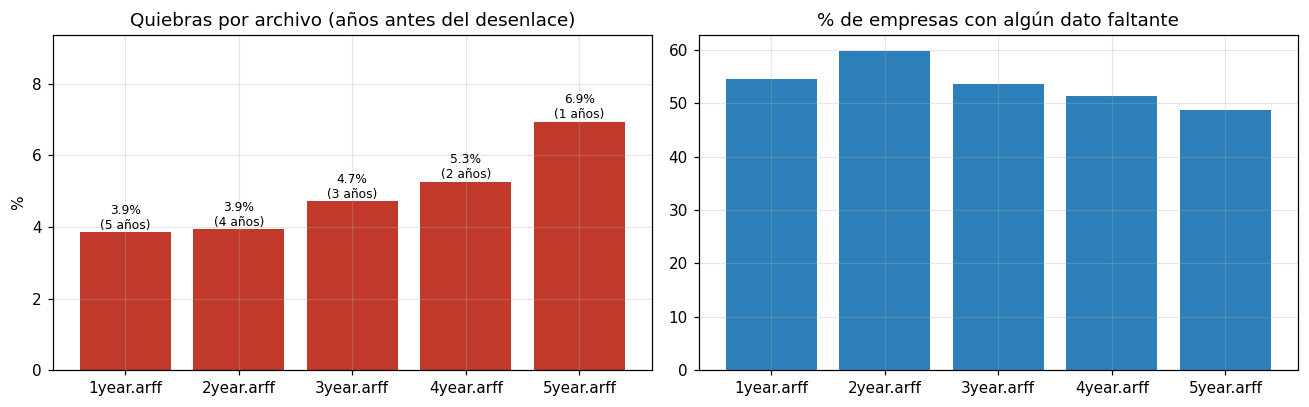

χ² de homogeneidad de la prevalencia entre archivos: χ² = 93.9, p = 2.0e-19 → la tasa de quiebra cambia con el horizonte (label shift).


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].bar(load_report["archivo"], load_report["prevalencia_%"], color="#c0392b")
for i, (v, h) in enumerate(zip(load_report["prevalencia_%"], load_report["horizonte_años"])):
    ax[0].text(i, v + 0.1, f"{v:.1f}%\n({h} años)", ha="center", fontsize=8)
ax[0].set_title("Quiebras por archivo (años antes del desenlace)")
ax[0].set_ylabel("%")
ax[0].set_ylim(0, load_report["prevalencia_%"].max() * 1.35)
ax[1].bar(load_report["archivo"], load_report["filas_con_NaN_%"], color="#2c7fb8")
ax[1].set_title("% de empresas con algún dato faltante")
plt.tight_layout()
plt.show()
chi2, pval, _, _ = stats.chi2_contingency(pd.crosstab(raw_df["cohort"], raw_df["class"]))
print(f"χ² de homogeneidad de la prevalencia entre archivos: χ² = {chi2:.1f}, p = {pval:.1e} → la tasa de quiebra cambia con el horizonte (label shift).")

### 1.6 Diagnóstico del orden de las filas (causa raíz de los resultados de TT1)
En TT1 se asumió que el orden dentro de cada archivo era temporal. La **prueba de rachas de Wald–Wolfowitz** evalúa si la secuencia de etiquetas parece aleatoria: z ≈ 0 indica orden aleatorio; |z| ≫ 3, orden sistemático.

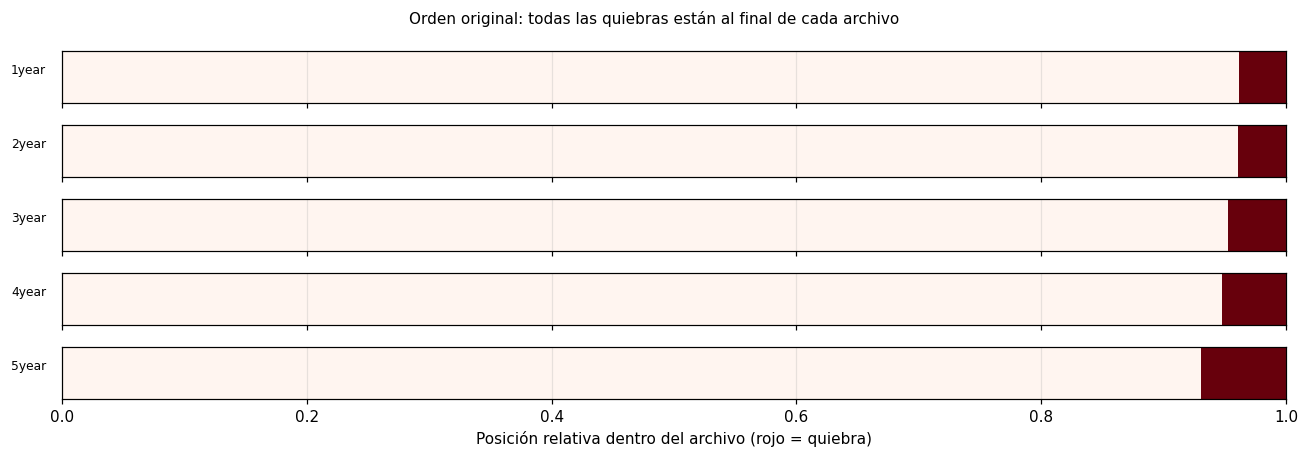

,cohorte,filas,quiebras,primera_fila_con_quiebra,quiebras_contiguas_al_final,z_rachas
0,1,7027,271,6756,True,-83.7
1,2,10173,400,9773,True,-100.8
2,3,10503,495,10008,True,-102.4
3,4,9792,515,9277,True,-98.9
4,5,5910,410,5500,True,-76.8


In [8]:
def runs_test_z(seq):
    """Prueba de rachas de Wald–Wolfowitz para una secuencia binaria."""
    s = np.asarray(seq).astype(int)
    n1, n = s.sum(), len(s)
    n0 = n - n1
    if n1 == 0 or n0 == 0:
        return np.nan
    runs = 1 + np.count_nonzero(np.diff(s))
    mu = 2 * n1 * n0 / n + 1
    var = 2 * n1 * n0 * (2 * n1 * n0 - n) / (n ** 2 * (n - 1))
    return (runs - mu) / np.sqrt(var)

order_diag = []
fig, axes = plt.subplots(5, 1, figsize=(12, 4.2), sharex=True)
for ax, (k, g) in zip(axes, raw_df.groupby("cohort")):
    y_seq = g.sort_values("row_in_file")["class"].to_numpy()
    pos = np.flatnonzero(y_seq)
    order_diag.append({"cohorte": k, "filas": len(y_seq), "quiebras": len(pos), "primera_fila_con_quiebra": int(pos.min()),
                       "quiebras_contiguas_al_final": bool(pos.min() == len(y_seq) - len(pos)),
                       "z_rachas": runs_test_z(y_seq)})
    ax.imshow(y_seq[None, :], aspect="auto", cmap="Reds", interpolation="nearest", extent=[0, 1, 0, 1])
    ax.set_yticks([])
    ax.set_ylabel(f"{k}year", rotation=0, labelpad=22, fontsize=8)
axes[-1].set_xlabel("Posición relativa dentro del archivo (rojo = quiebra)")
fig.suptitle("Orden original: todas las quiebras están al final de cada archivo", fontsize=10)
plt.tight_layout()
plt.show()
pd.DataFrame(order_diag).round(1)

**Consecuencia para TT1:**
- Con el orden original, las ventanas de producción contenían solo empresas sanas o solo quiebras.
- El AUC por ventana quedaba indefinido y la "recalibración" solo podía ejecutarse en las pocas ventanas de frontera.
- Los resultados de Polish en TT1 son por lo tanto un artefacto del orden de las filas.

### 1.7 Requisitos de un dataset candidato (observación 4) y corrección del orden
`validate_dataset()` convierte los criterios de selección en pruebas medibles, y se aplica a los tres datasets del proyecto:

| Requisito | Criterio verificable |
|---|---|
| R1 | Objetivo binario. |
| R2 | Eje temporal con ≥ 3 periodos. |
| R3 | Orden independiente de la etiqueta. |
| R4 | Tamaño suficiente para ≥ 20 bloques de monitoreo. |
| R5–R6 | Positivos suficientes por bloque y por buffer de recalibración. |
| R7 | Faltantes acotados. |
| R8 | Pocos duplicados. |
| R9 | Evidencia de no estacionariedad. |
| R10 | Ausencia de identificadores o fugas entre las variables. |

In [9]:
def validate_dataset(df, target, period_col, order_col, features, id_cols=(), block_size=500, min_blocks=20,
                     min_pos_block=25, min_pos_buffer=100, recal_buffer=2000, prod_frac=0.30,
                     max_missing=0.60, warn_missing=0.30, max_dup=0.01):
    """Checklist cuantitativo de idoneidad para estudiar calibration drift (✅ cumple · ⚠️ cumple con advertencia · ❌ no cumple)."""
    rows = []

    def add(req, crit, val, ok, warn=False):
        rows.append({"requisito": req, "criterio": crit, "valor": val, "estado": ("⚠️" if warn else "✅") if ok else "❌"})

    y = df[target]
    add("R1 Objetivo binario", "valores ⊆ {0,1}", str(sorted(y.unique().tolist())), set(y.unique()) <= {0, 1})
    n_per = df[period_col].nunique()
    add("R2 Eje temporal", "≥ 3 periodos ordenables", f"{n_per} periodos", n_per >= 3)
    zmax = np.nanmax([abs(runs_test_z(g.sort_values(order_col)[target])) for _, g in df.groupby(period_col)])
    add("R3 Orden independiente de la etiqueta", "|z| de rachas < 3 en cada periodo", f"máx |z| = {zmax:.1f}", zmax < 3)
    n_prod = int(len(df) * prod_frac)
    add("R4 Tamaño de producción", f"≥ {min_blocks} bloques de {block_size}", f"{n_prod // block_size} bloques", n_prod // block_size >= min_blocks)
    prev_prod = df.sort_values([period_col, order_col])[target].iloc[-n_prod:].mean()
    add("R5 Positivos por bloque", f"≥ {min_pos_block} esperados", f"{prev_prod * block_size:.0f}", prev_prod * block_size >= min_pos_block)
    add("R6 Positivos en buffer de recalibración", f"≥ {min_pos_buffer} en {recal_buffer} filas", f"{prev_prod * recal_buffer:.0f}",
        prev_prod * recal_buffer >= min_pos_buffer)
    miss = df[features].isna().mean()
    add("R7 Faltantes por variable", f"máx ≤ {max_missing:.0%} (⚠️ si > {warn_missing:.0%})", f"{miss.max():.1%} ({miss.idxmax()})",
        miss.max() <= max_missing, warn=miss.max() > warn_missing)
    dup = df.duplicated(subset=features).mean()
    add("R8 Duplicados exactos", f"≤ {max_dup:.0%}", f"{dup:.2%}", dup <= max_dup)
    _, p, _, _ = stats.chi2_contingency(pd.crosstab(df[period_col], df[target]))
    add("R9 Evidencia de no estacionariedad", "χ² de prevalencia entre periodos, p < 0.05", f"p = {p:.1e}", p < 0.05)
    leaked = [c for c in id_cols if c in features]
    add("R10 Sin identificadores ni fugas", "ninguna columna ID o post-desenlace entre las variables", ", ".join(leaked) or "ninguna", not leaked)
    return pd.DataFrame(rows)

VALIDATION_KW = dict(target="class", period_col="cohort", features=RAW_FEATURES,
                     id_cols=("row_in_file", "source_file", "cohort", "horizon_years"),
                     block_size=CONFIG["block_size"], recal_buffer=CONFIG["recal_buffer"],
                     prod_frac=1 - CONFIG["train_frac"] - CONFIG["cal_frac"])
validation_raw = validate_dataset(raw_df, order_col="row_in_file", **VALIDATION_KW)

def fix_order(df, seed):
    """Deduplica y aleatoriza el orden DENTRO de cada cohorte (no existe orden temporal intra-cohorte)."""
    key = pd.util.hash_pandas_object(df[RAW_FEATURES], index=False).to_numpy()
    n_conflict = int(df.assign(_k=key).groupby("_k")["class"].nunique().gt(1).sum())
    dedup = df.loc[~df.duplicated(subset=RAW_FEATURES, keep="first")]
    rng = np.random.default_rng(seed)
    parts = [rng.permutation(dedup.index[dedup["cohort"] == k].to_numpy()) for k in sorted(dedup["cohort"].unique())]
    out = dedup.loc[np.concatenate(parts)].reset_index(drop=True)
    out["order_in_cohort"] = out.groupby("cohort").cumcount()
    out["t_index"] = np.arange(len(out))
    info = {"filas_originales": len(df), "duplicados_eliminados": int(len(df) - len(dedup)),
            "grupos_duplicados_con_clase_en_conflicto": n_conflict, "filas_finales": len(out)}
    return out, info

with timed("deduplicacion_y_reordenamiento"):
    data, fix_info = fix_order(raw_df, SEED)
print(fix_info)
validation_fixed = validate_dataset(data, order_col="order_in_cohort", **VALIDATION_KW)
validation = validation_raw[["requisito", "criterio"]].assign(
    **{"TT1 · orden original": validation_raw["valor"] + "  " + validation_raw["estado"],
       "TT2 · corregido": validation_fixed["valor"] + "  " + validation_fixed["estado"]})
validation

⏱  deduplicacion_y_reordenamiento: 0.732 s  (RSS 459 MB)
{'filas_originales': 43405, 'duplicados_eliminados': 401, 'grupos_duplicados_con_clase_en_conflicto': 0, 'filas_finales': 43004}


,requisito,criterio,TT1 · orden original,TT2 · corregido
0,R1 Objetivo binario,"valores ⊆ {0,1}","[0, 1] ✅","[0, 1] ✅"
1,R2 Eje temporal,≥ 3 periodos ordenables,5 periodos ✅,5 periodos ✅
2,R3 Orden independiente de la etiqueta,|z| de rachas < 3 en cada periodo,máx |z| = 102.4 ❌,máx |z| = 1.2 ✅
3,R4 Tamaño de producción,≥ 20 bloques de 500,26 bloques ✅,25 bloques ✅
4,R5 Positivos por bloque,≥ 25 esperados,36 ✅,30 ✅
5,R6 Positivos en buffer de recalibración,≥ 100 en 2000 filas,142 ✅,120 ✅
6,R7 Faltantes por variable,máx ≤ 60% (⚠️ si > 30%),43.7% (Attr37) ⚠️,43.8% (Attr37) ⚠️
7,R8 Duplicados exactos,≤ 1%,0.92% ✅,0.00% ✅
8,R9 Evidencia de no estacionariedad,"χ² de prevalencia entre periodos, p < 0.05",p = 2.0e-19 ✅,p = 3.2e-19 ✅
9,R10 Sin identificadores ni fugas,ninguna columna ID o post-desenlace entre las ...,ninguna ✅,ninguna ✅


## 2. Preprocesamiento avanzado y feature engineering
### 2.1 Partición temporal 60/10/30
- Las empresas se ordenan por horizonte (5 → 1 años al desenlace) y se cortan en tres bloques contiguos que nunca se mezclan:
  - **train** (60 %): ajuste de modelos y de todas las transformaciones.
  - **calibración** (10 %): calibración inicial y selección de umbrales.
  - **producción** (30 %): simulación de operación.
- El horizonte **no** se usa como variable predictora:
  - Es el eje temporal del experimento.
  - Los horizontes de producción no aparecen en train, así que usarlo obligaría al modelo a extrapolar.

In [10]:
n = len(data)
i_tr = int(n * CONFIG["train_frac"])
i_ca = int(n * (CONFIG["train_frac"] + CONFIG["cal_frac"]))
data["split"] = np.where(data["t_index"] < i_tr, "train", np.where(data["t_index"] < i_ca, "calibration", "production"))
idx_tr = data.index[data["split"] == "train"].to_numpy()
idx_ca = data.index[data["split"] == "calibration"].to_numpy()
idx_pr = data.index[data["split"] == "production"].to_numpy()

with timed("construccion_variables"):
    X_all = build_features(data)
y_all = data["class"].to_numpy()
X_tr, y_tr = X_all.loc[idx_tr], y_all[idx_tr]
X_ca, y_ca = X_all.loc[idx_ca], y_all[idx_ca]
X_pr, y_pr = X_all.loc[idx_pr], y_all[idx_pr]

split_summary = (data.groupby(["split", "cohort"]).agg(filas=("class", "size"), quiebras=("class", "sum")).reset_index())
split_summary["prevalencia_%"] = 100 * split_summary["quiebras"] / split_summary["filas"]
tbl = data.pivot_table(index="split", columns="cohort", values="class", aggfunc="size", fill_value=0)
tbl = tbl.loc[["train", "calibration", "production"]]
tbl.columns = [f"{c}year" for c in tbl.columns]
tbl["total"] = tbl.sum(axis=1)
tbl["prevalencia_%"] = [100 * y.mean() for y in (y_tr, y_ca, y_pr)]
tbl.round(2)

⏱  construccion_variables: 0.108 s  (RSS 461 MB)


,1year,2year,3year,4year,5year,total,prevalencia_%
split,,,,,,,
train,6945,10083,8774,0,0,25802,4.19
calibration,0,0,1642,2658,0,4300,5.33
production,0,0,0,7052,5850,12902,5.99


### 2.2 Valores faltantes: ¿al azar o informativos?
Si la ausencia de un dato se relaciona con la quiebra (faltante *no al azar*, MNAR), imputar con la mediana sin más borra información. Todo el diagnóstico usa solo **train**.

AUC de 'número de faltantes' como único predictor (train): 0.657 → la ausencia de datos es informativa (MNAR).


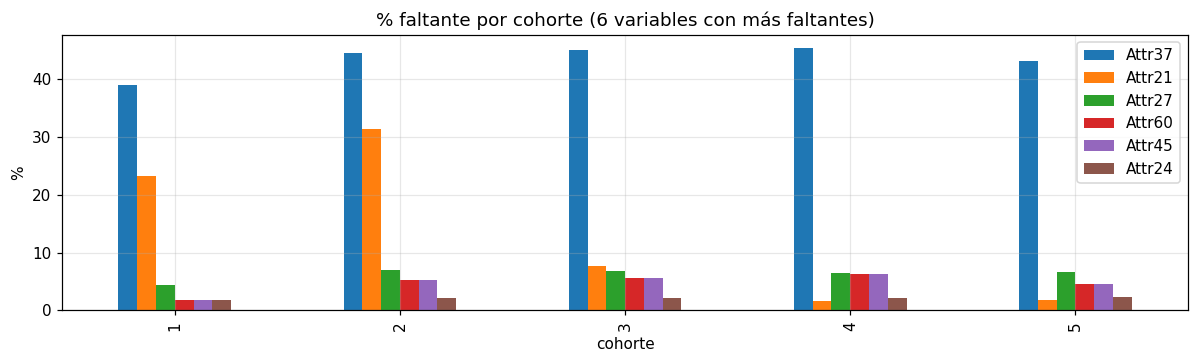

,faltante_train_%,faltante_si_quiebra_%,faltante_si_sana_%,descripción
Attr37,43.19,43.11,43.19,(Activo circulante − inventarios) / pasivos a ...
Attr21,21.12,34.88,20.52,Ventas (n) / ventas (n−1)
Attr27,6.28,37.84,4.90,Utilidad de operación / gastos financieros
Attr60,4.53,7.03,4.43,Ventas / inventario
Attr45,4.52,7.03,4.41,Utilidad neta / inventario
Attr24,2.06,0.00,2.15,Utilidad bruta (3 años) / activos totales
Attr41,1.77,0.00,1.84,Pasivos totales / ((utilidad de operación + de...
Attr28,1.68,2.87,1.63,Capital de trabajo / activos fijos
Attr53,1.68,2.87,1.63,Capital contable / activos fijos
Attr54,1.68,2.87,1.63,Capital permanente / activos fijos


In [11]:
miss_tr = X_tr[RAW_FEATURES].isna()
miss_tbl = pd.DataFrame({"faltante_train_%": 100 * miss_tr.mean(),
                         "faltante_si_quiebra_%": 100 * miss_tr[y_tr == 1].mean(),
                         "faltante_si_sana_%": 100 * miss_tr[y_tr == 0].mean(),
                         "descripción": pd.Series(FEATURE_LABELS)}).sort_values("faltante_train_%", ascending=False).head(10)
auc_nmiss = roc_auc_score(y_tr, X_tr["n_missing"])
print(f"AUC de 'número de faltantes' como único predictor (train): {auc_nmiss:.3f} → la ausencia de datos es informativa (MNAR).")
top_miss = miss_tbl.index[:6]
(100 * X_all[top_miss].isna().groupby(data["cohort"]).mean()).plot(
    kind="bar", figsize=(11, 3.4), title="% faltante por cohorte (6 variables con más faltantes)")
plt.ylabel("%")
plt.xlabel("cohorte")
plt.tight_layout()
plt.show()
miss_tbl.round(2)

### 2.3 Estrategia de imputación, transformación y desbalance

**Imputación: cada modelo recibe el tratamiento que su matemática requiere**
- *XGBoost*: faltantes **nativos**. En cada división el árbol aprende hacia qué rama enviar el NaN, y así aprovecha que la ausencia es informativa. Se añade `n_missing` (número de ratios faltantes).
- *Regresión logística*, en este orden:
  1. `asinh(x)`: logaritmo con signo, que comprime colas de ±10⁷.
  2. Imputación por **mediana de train** más **indicadores binarios de faltante** (conservan la señal MNAR).
  3. Estandarización.
  4. Winsorización a ±8 desviaciones.
- La ablación §3.6 compara estas opciones contra mediana sin indicadores y contra imputación iterativa (MICE).

**Desbalance (≈ 4–7 % de quiebras)**
- **No** se usan pesos de clase ni remuestreo (SMOTE, submuestreo): cambian la prevalencia que "ve" el modelo y desplazan sistemáticamente las probabilidades hacia arriba, lo que destruye la calibración.
- El desbalance se atiende donde corresponde:
  - Métricas centradas en la clase rara (AUC-PR, Brier Skill Score).
  - Validación estratificada en la calibración.
  - Umbral de decisión optimizado para *recall* (F2) en el split de calibración (§4.5).
- Si algún día se entrenara con peso *w* para la clase positiva, la probabilidad se corrige con p = p_w / (p_w + w·(1 − p_w)).

### 2.4 Codificación categórica
No es necesaria: los 64 predictores son ratios numéricos continuos. Las únicas columnas no numéricas (`source_file`, `cohort`) son metadatos del eje temporal y se excluyen del modelo (R10 del validador).

In [12]:
print(make_lr_pipeline(RAW_FEATURES + ["n_missing"], C=0.1, seed=SEED))

Pipeline(steps=[('select',
                 ColumnTransformer(transformers=[('sel', 'passthrough',
                                                  ['Attr1', 'Attr2', 'Attr3',
                                                   'Attr4', 'Attr5', 'Attr6',
                                                   'Attr7', 'Attr8', 'Attr9',
                                                   'Attr10', 'Attr11', 'Attr12',
                                                   'Attr13', 'Attr14', 'Attr15',
                                                   'Attr16', 'Attr17', 'Attr18',
                                                   'Attr19', 'Attr20', 'Attr21',
                                                   'Attr22', 'Attr23', 'Attr24',
                                                   'Attr25', 'Attr26', 'Attr27',
                                                   'Attr28', 'Attr29', 'Attr30', ...])],
                                   ve...
                ('asinh',
                 Function

### 2.5 ¿Análisis estático o con ajuste de dimensionalidad? (observación 6)
**Postura del proyecto:**
- El análisis exploratorio es **estático**: se hace una vez, sobre el histórico.
- El monitoreo es **dinámico**: por bloques de producción.
- El **esquema de variables se congela en cada versión del modelo**. Cualquier reducción de dimensionalidad se ajusta solo con train y se re-estima únicamente al reentrenar, con versión registrada.
- Entre reentrenamientos no cambia, para que las pruebas de drift comparen siempre las mismas variables.

**Técnica aplicada:**
- Los 64 ratios comparten numeradores y denominadores y son fuertemente colineales.
- Se agrupan por correlación de Spearman (|ρ| ≥ 0.90, enlace promedio, solo train).
- De cada grupo se conserva el representante con mayor AUC univariada.
- La **regresión logística** usa esos representantes: evita coeficientes inestables e ininterpretables.
- **XGBoost** usa los 64: los árboles no sufren colinealidad.
- La ablación §3.6 mide el efecto en desempeño y tiempo.

In [13]:
with timed("agrupamiento_colinealidad"):
    Xm = X_tr[RAW_FEATURES].fillna(X_tr[RAW_FEATURES].median())
    corr = Xm.rank().corr().abs().to_numpy(copy=True)
    dist = np.clip(1 - corr, 0, None)
    np.fill_diagonal(dist, 0.0)
    Z = linkage(squareform(dist, checks=False), method="average")
    clusters = fcluster(Z, t=1 - CONFIG["corr_threshold"], criterion="distance")
    auc_uni = pd.Series({c: roc_auc_score(y_tr, Xm[c]) for c in RAW_FEATURES})
    auc_uni = np.maximum(auc_uni, 1 - auc_uni)
    cl = pd.DataFrame({"variable": RAW_FEATURES, "grupo": clusters, "AUC_univariada": auc_uni.to_numpy()})
    reps = cl.sort_values("AUC_univariada", ascending=False).groupby("grupo").head(1)["variable"].tolist()
LR_FEATURES = [c for c in RAW_FEATURES if c in reps] + ["n_missing"]
print(f"{len(RAW_FEATURES)} ratios → {cl['grupo'].nunique()} grupos con |ρ| ≥ {CONFIG['corr_threshold']} (Spearman, solo train)")
print(f"Regresión logística: {len(LR_FEATURES)} variables (representantes + n_missing) · XGBoost: {len(MODEL_FEATURES)} variables")
multi = cl.groupby("grupo").filter(lambda g: len(g) > 1).sort_values(["grupo", "AUC_univariada"], ascending=[True, False])
multi.assign(representante=multi["variable"].isin(reps), descripción=multi["variable"].map(FEATURE_LABELS)).round(3)

⏱  agrupamiento_colinealidad: 3.358 s  (RSS 490 MB)
64 ratios → 38 grupos con |ρ| ≥ 0.9 (Spearman, solo train)
Regresión logística: 39 variables (representantes + n_missing) · XGBoost: 65 variables


,variable,grupo,AUC_univariada,representante,descripción
59,Attr60,6,0.533,True,Ventas / inventario
19,Attr20,6,0.516,False,(Inventario × 365) / ventas
46,Attr47,6,0.512,False,(Inventario × 365) / costo de ventas
43,Attr44,7,0.512,True,(Cuentas por cobrar × 365) / ventas
60,Attr61,7,0.510,False,Ventas / cuentas por cobrar
55,Attr56,12,0.623,True,(Ventas − costo de ventas) / ventas
57,Attr58,12,0.598,False,Costos totales / ventas totales
38,Attr39,13,0.651,True,Utilidad en ventas / ventas
41,Attr42,13,0.628,False,Utilidad de operación / ventas
48,Attr49,14,0.592,True,EBITDA (utilidad de operación − depreciación) ...


### 2.6 Population Stability Index (PSI) a través de los 5 horizontes
PSI = Σᵢ (qᵢ − pᵢ)·ln(qᵢ / pᵢ), donde *p* es la distribución de referencia y *q* la observada.

**Mejoras respecto de TT1:**
- **Bins por deciles de la referencia más un bin para faltantes**: un cambio en la tasa de faltantes también es drift (de calidad de datos).
- **Umbrales empíricos:** los umbrales 0.10 / 0.20 de la industria ignoran el tamaño de muestra y que se toma el máximo sobre 65 variables. Se estima la distribución nula de PSI_máx remuestreando train (sin drift por construcción) para cada tamaño de bloque, y se usan sus percentiles 95 (nivel 1) y 99 (nivel 2).

**Dos vistas:**
- (a) Cada archivo contra `1year`: la evolución a lo largo de los 5 horizontes.
- (b) Train contra calibración y producción: la referencia del monitor.

⏱  psi_por_cohorte: 0.334 s  (RSS 490 MB)


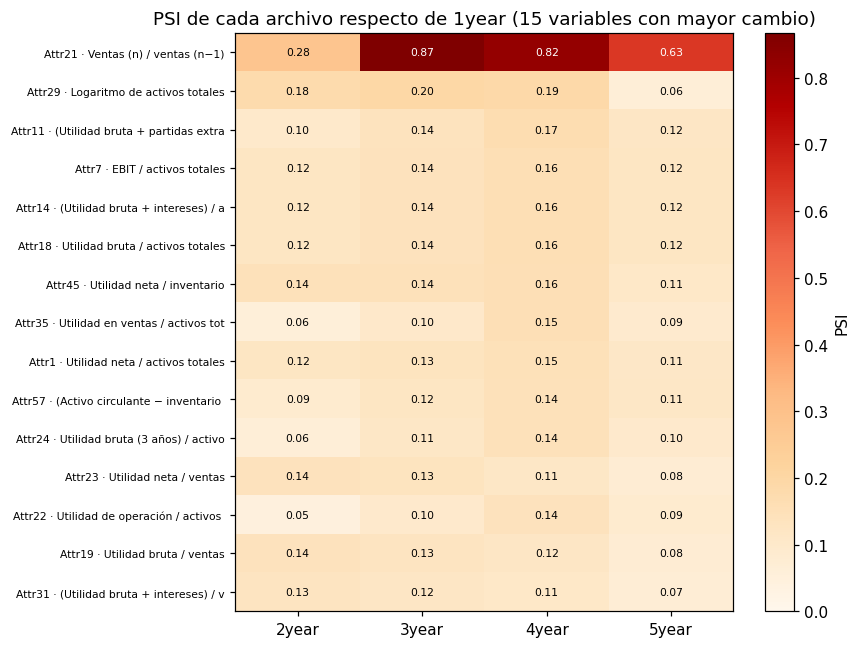

                          2year  3year  4year  5year
variables con PSI ≥ 0.10     14     17     19      8
variables con PSI ≥ 0.20      1      1      1      1


In [14]:
with timed("psi_por_cohorte"):
    ref_c1 = PSIReference(n_bins=CONFIG["psi_bins"]).fit(X_all.loc[data["cohort"] == 1, MODEL_FEATURES])
    psi_cohorts = pd.DataFrame({f"{k}year": ref_c1.transform(X_all.loc[data["cohort"] == k, MODEL_FEATURES]) for k in range(2, 6)})
top = psi_cohorts.max(axis=1).sort_values(ascending=False).head(15).index
vals = psi_cohorts.loc[top].to_numpy()
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(vals, cmap="OrRd", aspect="auto", vmin=0, vmax=max(0.25, vals.max()))
ax.set_xticks(range(vals.shape[1]))
ax.set_xticklabels(psi_cohorts.columns)
ax.set_yticks(range(len(top)))
ax.set_yticklabels([f"{t} · {FEATURE_LABELS[t][:32]}" for t in top], fontsize=7)
for i in range(vals.shape[0]):
    for j in range(vals.shape[1]):
        ax.text(j, i, f"{vals[i, j]:.2f}", ha="center", va="center", fontsize=7, color="white" if vals[i, j] > 0.5 else "black")
ax.grid(False)
plt.colorbar(im, label="PSI")
ax.set_title("PSI de cada archivo respecto de 1year (15 variables con mayor cambio)")
plt.tight_layout()
plt.show()
print(pd.DataFrame({"variables con PSI ≥ 0.10": (psi_cohorts >= 0.10).sum(), "variables con PSI ≥ 0.20": (psi_cohorts >= 0.20).sum()}).T)

In [15]:
with timed("psi_referencia_train_y_umbrales_nulos"):
    # Referencia = mitad aleatoria de train; distribución nula = bloques muestreados de la otra mitad (independientes).
    psi_train_ref, null_thr = fit_psi_monitor(X_tr[MODEL_FEATURES], CONFIG["psi_null_sizes"], B=CONFIG["psi_null_B"],
                                               seed=SEED, n_bins=CONFIG["psi_bins"])
    psi_null = pd.DataFrame([{"n": n_, **v} for n_, v in null_thr.items()])
    psi_splits = pd.DataFrame({"train→calibración": psi_train_ref.transform(X_ca[MODEL_FEATURES]),
                               "train→producción": psi_train_ref.transform(X_pr[MODEL_FEATURES])})
print("PSI por variable respecto de train (resumen):")
print(psi_splits.describe().T[["mean", "50%", "max"]].round(4))
print("\nTop-5 variables train→producción:")
top5 = psi_splits["train→producción"].sort_values(ascending=False).head(5)
print(pd.DataFrame({"PSI": top5.round(4), "descripción": top5.index.map(FEATURE_LABELS)}).to_string())
print("\nFaltantes de Attr21 por cohorte (%):", (100 * X_all["Attr21"].isna().groupby(data["cohort"]).mean()).round(1).to_dict())
print("\nUmbrales empíricos de PSI_máx (máximo sobre 65 variables) sin drift, según tamaño de muestra:")
psi_null.round(4)

⏱  psi_referencia_train_y_umbrales_nulos: 18.240 s  (RSS 492 MB)
PSI por variable respecto de train (resumen):
                     mean     50%     max
train→calibración  0.0211  0.0136  0.3323
train→producción   0.0217  0.0090  0.5770

Top-5 variables train→producción:
              PSI                                                                         descripción
Attr21     0.5770                                                           Ventas (n) / ventas (n−1)
n_missing  0.0384                                    Número de ratios faltantes (variable construida)
Attr22     0.0338                                             Utilidad de operación / activos totales
Attr35     0.0331                                                Utilidad en ventas / activos totales
Attr11     0.0327  (Utilidad bruta + partidas extraordinarias + gastos financieros) / activos totales

Faltantes de Attr21 por cohorte (%): {1: 23.2, 2: 31.3, 3: 7.7, 4: 1.6, 5: 1.8}

Umbrales empíricos de PSI_máx (máx

,n,media,p95,p99
0,500,0.0489,0.0665,0.0746
1,1000,0.0255,0.0347,0.0391
2,2000,0.0141,0.0189,0.0206


**Lectura:**
- **A lo largo de los 5 horizontes:**
  - Los ratios de rentabilidad cambian moderadamente (PSI ≈ 0.10–0.17 frente a `1year`).
  - `Attr21` (ventas n / n−1) cambia con fuerza, pero su cambio no es de valores sino de **disponibilidad**: falta en 23–31 % de las empresas en los horizontes lejanos y en ~2 % en los cercanos.
  - Es drift de *calidad de datos*, visible gracias al bin de faltantes.
- **Frente a train** (que ya mezcla los horizontes 5 a 3), la mediana del PSI en producción es < 0.01: salvo `Attr21`, la distribución de *X* cambia poco. Lo que sí cambia es la **prevalencia** (≈ 4.2 % → 6.0 %) y la relación ratios→quiebra. Por eso el monitor (§4.6) no depende solo del PSI de variables.
- **Umbrales:**
  - El umbral empírico depende del tamaño de muestra (p99 ≈ 0.07 con 500 empresas, ≈ 0.02 con 2 000), así que un 0.10 fijo es demasiado laxo para lotes grandes.
  - El monitor saturado de TT1 no se debía a los umbrales sino al orden de las filas (§1.6).

## 3. Modelado y justificación
### 3.1 ¿Por qué Regresión Logística como baseline y XGBoost como modelo avanzado? (observación 2)

**Regresión logística — baseline interpretable**
- Minimiza la log-verosimilitud, una *regla de puntuación propia*: bien especificada, produce probabilidades calibradas por construcción (Niculescu-Mizil & Caruana, 2005).
- Sus coeficientes se leen como razones de momios, lo que permite explicar en el dashboard *por qué* sube el riesgo de una empresa.
- Tiene baja varianza y se reentrena en milisegundos: es la referencia de costo mínimo para las políticas de intervención.
- Con 64 ratios colineales y de colas extremas exige un preprocesamiento explícito (§2.3–2.5); por eso es también el banco de pruebas del efecto del preprocesamiento.

**XGBoost — modelo avanzado**
- Es el estado del arte en datos tabulares de tamaño medio. Los ensambles de árboles superan a las redes profundas en benchmarks tabulares (Grinsztajn et al., NeurIPS 2022; Chen & Guestrin, KDD 2016).
- Es invariante a transformaciones monótonas: tolera ratios de ±10⁷ sin escalar ni recortar.
- Maneja faltantes de forma nativa y aprovecha que la ausencia de datos es informativa (§2.2).
- Captura no linealidades e interacciones entre ratios (por ejemplo, apalancamiento × rentabilidad) sin ingeniería manual.
- Se reentrena en segundos, lo que hace viable la política de reentrenamiento sobre muchos bloques.

**Por qué el par:** cubren los dos extremos del espectro (baja capacidad con buena calibración de origen frente a alta capacidad con calibración imperfecta). Si ambos se degradan distinto bajo el mismo drift, el fenómeno depende de la familia de modelo, que es una conclusión que el proyecto quiere poder afirmar.

**Decisiones de configuración (iguales en los tres datasets del proyecto)**
- Sin pesos de clase ni remuestreo (§2.3; demostrado en §3.6).
- XGBoost:
  - Hiperparámetros conservadores (profundidad 4, tasa 0.05, submuestreo 0.8, `min_child_weight` 5).
  - Número de árboles por *early stopping* en una validación temporal interna (último 15 % de train).
  - Reajuste final con todo train.
- Regresión logística: C elegido por log-loss en esa misma validación interna.
- Candidatos descartados (con evidencia en §3.7):
  - Random Forest: probabilidades por votación, sesgadas lejos de 0 y 1.
  - Redes neuronales: inferiores en tabular, costosas de reentrenar y con sobreconfianza conocida (Guo et al., 2017).
  - SVM: sin probabilidades nativas.

### 3.2 Matrices y validación temporal interna

In [16]:
n_fit = int(len(idx_tr) * (1 - CONFIG["inner_val_frac"]))
idx_fit, idx_val = idx_tr[:n_fit], idx_tr[n_fit:]
X_fit, y_fit = X_all.loc[idx_fit], y_all[idx_fit]
X_val, y_val = X_all.loc[idx_val], y_all[idx_val]
print(f"Ajuste: {len(idx_fit):,} filas (prevalencia {y_fit.mean():.2%}) · Validación interna: {len(idx_val):,} filas "
      f"(prevalencia {y_val.mean():.2%}, cohortes {sorted(data.loc[idx_val, 'cohort'].unique().tolist())})")

Ajuste: 21,931 filas (prevalencia 4.09%) · Validación interna: 3,871 filas (prevalencia 4.78%, cohortes [3])


### 3.3 Entrenamiento de la Regresión Logística (con medición de tiempo)

In [17]:
%%time
with timed("LR_seleccion_de_C", modelo="LR"):
    lr_search = []
    for C in CONFIG["lr_C_grid"]:
        pipe = make_lr_pipeline(LR_FEATURES, C=C, seed=SEED).fit(X_fit, y_fit)
        p = pipe.predict_proba(X_val)[:, 1]
        lr_search.append({"C": C, "LogLoss_val": log_loss(y_val, p), "AUC_val": roc_auc_score(y_val, p),
                          "AP_val": average_precision_score(y_val, p)})
    lr_search = pd.DataFrame(lr_search)
    best_C = float(lr_search.loc[lr_search["LogLoss_val"].idxmin(), "C"])
with timed("LR_entrenamiento_final", modelo="LR"):
    lr_model = make_lr_pipeline(LR_FEATURES, C=best_C, seed=SEED).fit(X_tr, y_tr)
print(f"C seleccionado: {best_C}")
display(lr_search.round(4))

⏱  LR_seleccion_de_C: 2.990 s  (RSS 527 MB)
⏱  LR_entrenamiento_final: 1.093 s  (RSS 552 MB)
C seleccionado: 0.01


,C,LogLoss_val,AUC_val,AP_val
0,0.01,0.1514,0.8332,0.3253
1,0.10,0.1526,0.8185,0.3529
2,1.00,0.1568,0.8101,0.3645


CPU times: user 3.89 s, sys: 32.9 ms, total: 3.92 s
Wall time: 4.15 s


### 3.4 Entrenamiento de XGBoost (con medición de tiempo)

⏱  XGB_early_stopping: 17.207 s  (RSS 524 MB)
⏱  XGB_entrenamiento_final: 6.705 s  (RSS 526 MB)
Árboles seleccionados: 625 · validación interna → LogLoss 0.0847 · AUC 0.9582 · AP 0.7594


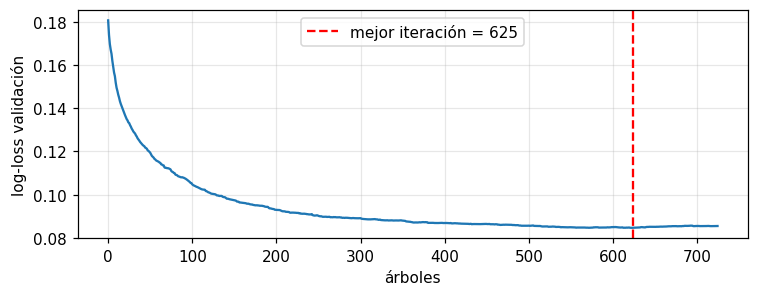

CPU times: user 40.1 s, sys: 109 ms, total: 40.2 s
Wall time: 24.2 s


In [18]:
%%time
with timed("XGB_early_stopping", modelo="XGB"):
    xgb_es = XGBClassifier(**XGB_PARAMS, n_estimators=CONFIG["xgb_max_rounds"],
                           early_stopping_rounds=CONFIG["xgb_early_stopping"], eval_metric="logloss")
    xgb_es.fit(X_fit[MODEL_FEATURES], y_fit, eval_set=[(X_val[MODEL_FEATURES], y_val)], verbose=False)
    best_iter = int(xgb_es.best_iteration) + 1
with timed("XGB_entrenamiento_final", modelo="XGB"):
    xgb_model = XGBClassifier(**XGB_PARAMS, n_estimators=best_iter).fit(X_tr[MODEL_FEATURES], y_tr)
p_val = xgb_es.predict_proba(X_val[MODEL_FEATURES])[:, 1]
print(f"Árboles seleccionados: {best_iter} · validación interna → LogLoss {log_loss(y_val, p_val):.4f} · "
      f"AUC {roc_auc_score(y_val, p_val):.4f} · AP {average_precision_score(y_val, p_val):.4f}")
curve = xgb_es.evals_result()["validation_0"]["logloss"]
plt.figure(figsize=(7, 2.8))
plt.plot(curve)
plt.axvline(best_iter - 1, color="r", ls="--", label=f"mejor iteración = {best_iter}")
plt.xlabel("árboles")
plt.ylabel("log-loss validación")
plt.legend()
plt.tight_layout()
plt.show()

### 3.5 Protocolo de medición de tiempos (observación 1)
Un solo cronometraje es ruidoso. Por eso cada entrenamiento se repite `timing_repeats` veces y cada inferencia 5 veces, y se reportan mediana, mínimo y máximo junto con el hardware. Las etapas de todo el notebook quedan además en `TIMINGS` (§5.5).

In [19]:
def repeat_timing(fn, repeats):
    out = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        fn()
        out.append(time.perf_counter() - t0)
    return np.array(out)

R_T = CONFIG["timing_repeats"]
X_inf = X_pr.iloc[:1000]
ops = [("LR · entrenamiento (train completo)", len(X_tr), R_T, lambda: make_lr_pipeline(LR_FEATURES, C=best_C, seed=SEED).fit(X_tr, y_tr)),
       ("XGB · entrenamiento (train completo)", len(X_tr), R_T, lambda: XGBClassifier(**XGB_PARAMS, n_estimators=best_iter).fit(X_tr[MODEL_FEATURES], y_tr)),
       ("Construcción de variables", 1000, 5, lambda: build_features(data.loc[idx_pr[:1000]])),
       ("LR · inferencia", 1000, 5, lambda: lr_model.predict_proba(X_inf)),
       ("XGB · inferencia", 1000, 5, lambda: xgb_model.predict_proba(X_inf[MODEL_FEATURES]))]
with timed("protocolo_de_tiempos"):
    rows = []
    for name, n_rows, reps, fn in ops:
        ts = repeat_timing(fn, reps)
        rows.append({"operación": name, "filas": n_rows, "repeticiones": reps, "mediana_s": np.median(ts),
                     "min_s": ts.min(), "max_s": ts.max(), "ms_por_1000_filas": 1000 * np.median(ts) / n_rows * 1000})
timing_protocol = pd.DataFrame(rows)
print(f"Hardware: {ENV['procesador']} · {ENV['cpus_logicos']} CPU lógicos · {ENV['ram_gb']} GB RAM · "
      f"xgboost {ENV['xgboost']} · scikit-learn {ENV['scikit-learn']} · n_jobs = {CONFIG['n_jobs']}")
timing_protocol.round(4)

⏱  protocolo_de_tiempos: 25.453 s  (RSS 508 MB)
Hardware: x86_64 · 2 CPU lógicos · 13.6 GB RAM · xgboost 3.4.1 · scikit-learn 1.6.1 · n_jobs = 2


,operación,filas,repeticiones,mediana_s,min_s,max_s,ms_por_1000_filas
0,LR · entrenamiento (train completo),25802,3,0.5182,0.4115,0.5432,20.0836
1,XGB · entrenamiento (train completo),25802,3,8.5060,6.7123,8.6155,329.6635
2,Construcción de variables,1000,5,0.0081,0.0078,0.0107,8.0752
3,LR · inferencia,1000,5,0.0044,0.0043,0.0050,4.4443
4,XGB · inferencia,1000,5,0.0159,0.0157,0.0159,15.8592


### 3.6 Ablaciones: evidencia de cada decisión de diseño
Cada variante cambia **una sola** decisión respecto de la configuración TT2 y se evalúa en el split de **calibración**. El split de producción queda intacto para la evaluación final.

| Variante | Qué pone a prueba |
|---|---|
| Pesos de clase (como TT1) | ¿Mejoran la discriminación? ¿Qué le hacen a la calibración (ECE, prob. media vs prevalencia)? |
| Imputación | Mediana sin indicadores vs mediana + indicadores vs MICE iterativa. |
| Dimensionalidad | 64 ratios completos vs un representante por grupo colineal. |
| XGBoost | NaN nativo vs imputación por mediana. |

In [20]:
def eval_row(name, y, p, secs):
    m = evaluate_probs(y, p)
    return {"variante": name, "AUC": m["AUC"], "AP": m["AP"], "ECE": m["ECE"], "Brier": m["Brier"],
            "LogLoss": m["LogLoss"], "prob_media": m["p_media"], "prevalencia": m["prevalencia"], "ajuste_s": secs}

spw = (y_tr == 0).sum() / (y_tr == 1).sum()
med_tr = X_tr[MODEL_FEATURES].median()
variants = [
    ("LR · TT2 (asinh + mediana + indicadores, sin pesos, representantes)", "lr", lambda: make_lr_pipeline(LR_FEATURES, C=best_C, seed=SEED)),
    ("LR · class_weight='balanced' (como TT1)", "lr", lambda: make_lr_pipeline(LR_FEATURES, C=best_C, class_weight="balanced", seed=SEED)),
    ("LR · mediana sin indicadores de faltante", "lr", lambda: make_lr_pipeline(LR_FEATURES, C=best_C, imputer="median_sin_indicadores", seed=SEED)),
    ("LR · imputación iterativa (MICE) + indicadores", "lr", lambda: make_lr_pipeline(LR_FEATURES, C=best_C, imputer="iterativo", seed=SEED)),
    ("LR · 64 ratios completos (sin reducción)", "lr", lambda: make_lr_pipeline(RAW_FEATURES + ["n_missing"], C=best_C, seed=SEED)),
    ("XGB · TT2 (NaN nativo, sin pesos)", "xgb", lambda: XGBClassifier(**XGB_PARAMS, n_estimators=best_iter)),
    (f"XGB · scale_pos_weight = {spw:.1f} (como TT1)", "xgb", lambda: XGBClassifier(**XGB_PARAMS, n_estimators=best_iter, scale_pos_weight=spw)),
    ("XGB · imputación por mediana", "xgb_med", lambda: XGBClassifier(**XGB_PARAMS, n_estimators=best_iter)),
]
abl = []
with timed("ablaciones"):
    for name, kind, make in variants:
        t0 = time.perf_counter()
        if kind == "lr":
            p = make().fit(X_tr, y_tr).predict_proba(X_ca)[:, 1]
        elif kind == "xgb":
            p = make().fit(X_tr[MODEL_FEATURES], y_tr).predict_proba(X_ca[MODEL_FEATURES])[:, 1]
        else:
            p = make().fit(X_tr[MODEL_FEATURES].fillna(med_tr), y_tr).predict_proba(X_ca[MODEL_FEATURES].fillna(med_tr))[:, 1]
        abl.append(eval_row(name, y_ca, p, time.perf_counter() - t0))
ablation = pd.DataFrame(abl)
ablation.round(4)

⏱  ablaciones: 34.438 s  (RSS 601 MB)


,variante,AUC,AP,ECE,Brier,LogLoss,prob_media,prevalencia,ajuste_s
0,"LR · TT2 (asinh + mediana + indicadores, sin p...",0.8463,0.3602,0.0148,0.0420,0.1617,0.0410,0.0533,0.4800
1,LR · class_weight='balanced' (como TT1),0.8806,0.2697,0.2495,0.1320,0.4557,0.3028,0.0533,0.6226
2,LR · mediana sin indicadores de faltante,0.8070,0.2044,0.0156,0.0474,0.1810,0.0403,0.0533,0.3424
3,LR · imputación iterativa (MICE) + indicadores,0.8471,0.3676,0.0145,0.0417,0.1606,0.0413,0.0533,7.3762
4,LR · 64 ratios completos (sin reducción),0.8494,0.3713,0.0154,0.0415,0.1608,0.0408,0.0533,0.7629
5,"XGB · TT2 (NaN nativo, sin pesos)",0.9588,0.7667,0.0153,0.0247,0.0929,0.0385,0.0533,8.7556
6,XGB · scale_pos_weight = 22.9 (como TT1),0.9568,0.7698,0.0378,0.0267,0.1044,0.0910,0.0533,8.4865
7,XGB · imputación por mediana,0.9537,0.7577,0.0149,0.0246,0.0945,0.0388,0.0533,7.3110


**Lectura de las ablaciones (split de calibración):**
- **Pesos de clase:**
  - La probabilidad media se dispara por encima de la prevalencia real (LR ≈ 0.30 frente a 0.053) y el ECE se multiplica (≈ 17× en LR, ≈ 2.5× en XGB).
  - En la LR, `balanced` sube algo el AUC pero **baja el AP**, la métrica relevante con clase rara.
  - Los pesos no mejoran la detección de quiebras y sí falsean las probabilidades: TT2 los elimina.
- **Imputación:**
  - Los indicadores de faltante suben el AP de la LR de ≈ 0.20 a ≈ 0.36 (la ausencia es informativa).
  - MICE iguala a mediana + indicadores pero tarda ~17× más; se elige la opción simple.
- **Dimensionalidad:** los 64 ratios dan un AP apenas mayor que los representantes (≈ 0.37 vs 0.36). Se acepta esa diferencia a cambio de coeficientes estables e interpretables. XGBoost usa las 65 variables.
- **XGBoost:** con NaN nativo supera levemente a imputar con la mediana, lo que confirma que la ausencia aporta señal.

### 3.7 Benchmark ampliado de candidatos (evidencia para la observación 2)

In [21]:
bench = []
if CONFIG["run_extended_benchmark"]:
    with timed("benchmark_ampliado"):
        pre = make_lr_pipeline(RAW_FEATURES + ["n_missing"], C=1.0, seed=SEED)[:-1].fit(X_tr)
        Z_tr, Z_ca = pre.transform(X_tr), pre.transform(X_ca)
        candidates = [
            ("Regresión logística (TT2)", "lr", None),
            ("XGBoost (TT2)", "xgb", None),
            ("Random Forest (300 árboles)", "Z", RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=CONFIG["n_jobs"], random_state=SEED)),
            ("HistGradientBoosting (sklearn)", "raw", HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, early_stopping=True, random_state=SEED)),
            ("MLP (64-32, early stopping)", "Z", MLPClassifier(hidden_layer_sizes=(64, 32), early_stopping=True, max_iter=300, random_state=SEED)),
        ]
        for name, kind, est in candidates:
            t0 = time.perf_counter()
            if kind == "lr":
                p = make_lr_pipeline(LR_FEATURES, C=best_C, seed=SEED).fit(X_tr, y_tr).predict_proba(X_ca)[:, 1]
            elif kind == "xgb":
                p = XGBClassifier(**XGB_PARAMS, n_estimators=best_iter).fit(X_tr[MODEL_FEATURES], y_tr).predict_proba(X_ca[MODEL_FEATURES])[:, 1]
            elif kind == "raw":
                p = est.fit(X_tr[MODEL_FEATURES], y_tr).predict_proba(X_ca[MODEL_FEATURES])[:, 1]
            else:
                p = est.fit(Z_tr, y_tr).predict_proba(Z_ca)[:, 1]
            bench.append(eval_row(name, y_ca, p, time.perf_counter() - t0))
benchmark = pd.DataFrame(bench)
benchmark.sort_values("LogLoss").round(4) if len(benchmark) else "Benchmark ampliado desactivado en CONFIG"

⏱  benchmark_ampliado: 84.354 s  (RSS 653 MB)


,variante,AUC,AP,ECE,Brier,LogLoss,prob_media,prevalencia,ajuste_s
1,XGBoost (TT2),0.9588,0.7667,0.0153,0.0247,0.0929,0.0385,0.0533,8.6717
3,HistGradientBoosting (sklearn),0.9482,0.7377,0.0165,0.0255,0.1002,0.0367,0.0533,4.3849
2,Random Forest (300 árboles),0.9147,0.6060,0.0166,0.0335,0.1264,0.0471,0.0533,56.6363
4,"MLP (64-32, early stopping)",0.9399,0.7429,0.0213,0.0238,0.1326,0.0349,0.0533,13.5718
0,Regresión logística (TT2),0.8463,0.3602,0.0148,0.0420,0.1617,0.0410,0.0533,0.4278


**Lectura del benchmark:**
- XGBoost obtiene la menor log-loss y el mayor AUC/AP.
- HistGradientBoosting, de la misma familia, queda cerca: la ventaja es del *boosting* de árboles, no de una implementación.
- Random Forest es ~8× más lento que XGBoost y tiene un AP claramente menor.
- La MLP no supera a XGBoost y su log-loss es mayor.
- La LR queda como baseline interpretable y barato, con AP muy inferior.
- Este contraste es precisamente lo que justifica el par elegido.

## 4. Calibración y evaluación avanzada
### 4.1 Selección del calibrador en el split de calibración
| Método | Qué hace | Cuándo conviene |
|---|---|---|
| `none` | Deja la probabilidad del modelo. | Si el modelo ya está calibrado. |
| `temperature` | σ(logit(p)/T): un parámetro, escala la confianza. | Sobre/subconfianza simétrica. No corrige cambios de prevalencia. |
| `platt` | σ(a·logit(p)+b): escala **y** sesgo. | Poca data y desplazamientos de prevalencia (label shift). |
| `isotonic` | Función monótona no paramétrica. | Mucha data; con pocas quiebras tiende a sobreajustar. |

**Procedimiento de elección:**
- Se elige por **log-loss con validación cruzada estratificada de 5 pliegues dentro del split de calibración** (predicciones fuera de pliegue).
- Después se ajusta el calibrador elegido con todo el split.
- El modelo recomendado para el dashboard se escoge con el mismo criterio. La elección ocurre **sin mirar producción**.

In [22]:
def crossfit_calibrators(p_raw, y, methods, n_splits, seed):
    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=seed)
    oof = {m: np.zeros_like(p_raw) for m in methods}
    for tr_i, te_i in skf.split(p_raw.reshape(-1, 1), y):
        for m in methods:
            oof[m][te_i] = make_calibrator(m).fit(p_raw[tr_i], y[tr_i]).predict(p_raw[te_i])
    rows = [{"método": m, "LogLoss": log_loss(y, oof[m]), "Brier": np.mean((oof[m] - y) ** 2),
             "ECE": ece_uniform(y, oof[m]), "ACE": polish_tt2.ace_equal_mass(y, oof[m])} for m in methods]
    return pd.DataFrame(rows), oof

MODELS = {"lr": lr_model, "xgb": xgb_model}

def raw_scores(kind, model, X):
    return model.predict_proba(X[MODEL_FEATURES] if kind == "xgb" else X)[:, 1]

raw_cal = {k: raw_scores(k, m, X_ca) for k, m in MODELS.items()}
calib_rows, OOF, CALIBRATOR, CAL_METHOD = [], {}, {}, {}
with timed("seleccion_y_ajuste_de_calibradores"):
    for kind, p in raw_cal.items():
        tbl_c, oof = crossfit_calibrators(p, y_ca, CONFIG["calib_methods"], CONFIG["calib_cv_folds"], SEED)
        tbl_c.insert(0, "modelo", kind.upper())
        calib_rows.append(tbl_c)
        CAL_METHOD[kind] = tbl_c.loc[tbl_c["LogLoss"].idxmin(), "método"]
        OOF[kind] = oof[CAL_METHOD[kind]]
        CALIBRATOR[kind] = make_calibrator(CAL_METHOD[kind]).fit(p, y_ca)
calib_sel = pd.concat(calib_rows, ignore_index=True)
cv_best = calib_sel.loc[calib_sel.groupby("modelo")["LogLoss"].idxmin()].sort_values("LogLoss")
BEST_KIND = cv_best.iloc[0]["modelo"].lower()
for k, c in CALIBRATOR.items():
    params = {a: round(getattr(c, a), 4) for a in ("T_", "a_", "b_") if hasattr(c, a)}
    print(f"{k.upper()}: calibrador elegido = {CAL_METHOD[k]} {params}")
print(f"Modelo recomendado para el dashboard: {BEST_KIND.upper()} (menor log-loss validada en el split de calibración)")
calib_sel.round(4)

⏱  seleccion_y_ajuste_de_calibradores: 0.171 s  (RSS 653 MB)
LR: calibrador elegido = platt {'a_': 1.0258, 'b_': 0.4021}
XGB: calibrador elegido = platt {'a_': 1.2404, 'b_': 1.3996}
Modelo recomendado para el dashboard: XGB (menor log-loss validada en el split de calibración)


,modelo,método,LogLoss,Brier,ECE,ACE
0,LR,none,0.1617,0.0420,0.0148,0.0169
1,LR,temperature,0.1603,0.0417,0.0066,0.0164
2,LR,platt,0.1598,0.0416,0.0084,0.0111
3,LR,isotonic,0.1623,0.0413,0.0064,0.0070
4,XGB,none,0.0929,0.0247,0.0153,0.0153
5,XGB,temperature,0.0912,0.0243,0.0107,0.0124
6,XGB,platt,0.0860,0.0229,0.0055,0.0009
7,XGB,isotonic,0.0914,0.0233,0.0066,0.0023


### 4.2 Evaluación en producción con intervalos de confianza (incluye KS)
Todas las métricas se calculan sobre el 30 % de producción, nunca visto durante el ajuste. Los intervalos al 95 % se obtienen por bootstrap.

| Métrica | Qué mide | Ideal |
|---|---|---|
| **AUC** | Probabilidad de que una quiebra reciba mayor score que una empresa sana. | 1 |
| **AP** (AUC-PR) | Precisión promedio en la clase rara. | 1 (azar = prevalencia) |
| **Brier / BSS** | Error cuadrático de la probabilidad / mejora sobre predecir siempre la prevalencia de train. | 0 / > 0 |
| **ECE / ACE / MCE** | Brecha entre probabilidad y frecuencia real (bins uniformes / de igual masa / peor bin). | 0 |
| **CITL / Pendiente** | Calibración en lo grande / dispersión de las probabilidades. | 0 / 1 |
| **O/E** | Quiebras observadas / esperadas. | 1 |
| **KS** | Máxima separación entre las distribuciones de score de quiebras y sanas, con su p-valor (Kolmogorov–Smirnov de dos muestras). | 1 |

In [23]:
def bootstrap_ci(y, p, B, seed, fns):
    rng, n_ = np.random.default_rng(seed), len(y)
    res = {k: [] for k in fns}
    for _ in range(B):
        i = rng.integers(0, n_, n_)
        if y[i].min() == y[i].max():
            continue
        for k, f in fns.items():
            res[k].append(f(y[i], p[i]))
    return {k: np.percentile(v, [2.5, 97.5]) for k, v in res.items()}

CI_FNS = {"AUC": roc_auc_score, "AP": average_precision_score, "Brier": lambda y, p: np.mean((p - y) ** 2), "ECE": ece_uniform}
prior_train = y_tr.mean()
PROD_PROBS = {}
for k, m in MODELS.items():
    PROD_PROBS[f"{k.upper()} · sin calibrar"] = raw_scores(k, m, X_pr)
    PROD_PROBS[f"{k.upper()} · calibrada ({CAL_METHOD[k]})"] = CALIBRATOR[k].predict(PROD_PROBS[f"{k.upper()} · sin calibrar"])

rows = []
with timed("evaluacion_produccion_bootstrap"):
    for name, p in PROD_PROBS.items():
        m = evaluate_probs(y_pr, p, prior=prior_train)
        ci = bootstrap_ci(y_pr, p, CONFIG["bootstrap_B"], SEED, CI_FNS)
        row = {"modelo": name}
        for k in ["AUC", "AP", "Brier", "ECE"]:
            row[k] = f"{m[k]:.4f} [{ci[k][0]:.4f}, {ci[k][1]:.4f}]"
        row.update({k: round(m[k], 4) for k in ["BSS", "LogLoss", "ACE", "MCE", "CITL", "Pendiente", "O/E", "KS"]})
        row["KS_p"] = f"{m['KS_p']:.1e}"
        rows.append(row)
metrics_production = pd.DataFrame(rows)
print(f"Producción: {len(y_pr):,} empresas · {int(y_pr.sum())} quiebras ({y_pr.mean():.2%}) · prevalencia en train {prior_train:.2%}")
metrics_production

⏱  evaluacion_produccion_bootstrap: 10.914 s  (RSS 653 MB)
Producción: 12,902 empresas · 773 quiebras (5.99%) · prevalencia en train 4.19%


,modelo,AUC,AP,Brier,ECE,BSS,LogLoss,ACE,MCE,CITL,Pendiente,O/E,KS,KS_p
0,LR · sin calibrar,"0.8554 [0.8416, 0.8715]","0.4207 [0.3886, 0.4577]","0.0456 [0.0424, 0.0486]","0.0217 [0.0180, 0.0253]",0.1945,0.1744,0.0227,0.2626,0.5407,1.1297,1.5248,0.5637,1.7e-218
1,LR · calibrada (platt),"0.8554 [0.8416, 0.8715]","0.4207 [0.3886, 0.4577]","0.0445 [0.0414, 0.0475]","0.0118 [0.0083, 0.0157]",0.2146,0.1692,0.0160,0.1660,0.2117,1.1013,1.1750,0.5637,1.7e-218
2,XGB · sin calibrar,"0.9636 [0.9560, 0.9695]","0.8025 [0.7767, 0.8264]","0.0275 [0.0251, 0.0300]","0.0206 [0.0178, 0.0234]",0.5148,0.1007,0.0211,0.5411,0.9478,1.3534,1.5249,0.7974,0.0e+00
3,XGB · calibrada (platt),"0.9636 [0.9560, 0.9695]","0.8025 [0.7767, 0.8264]","0.0236 [0.0214, 0.0259]","0.0059 [0.0045, 0.0090]",0.5831,0.0878,0.0062,0.2165,0.2497,1.0910,1.1065,0.7974,0.0e+00


**Lectura:**
- La calibración de Platt reduce el ECE de XGBoost de ≈ 0.021 a ≈ 0.006 y acerca la pendiente a 1, sin tocar AUC ni AP (es una transformación monótona).
- En producción O/E ≈ 1.1: el modelo aún subestima levemente las quiebras porque la prevalencia de producción (≈ 6.0 %) supera a la del split de calibración (≈ 5.3 %). Es el drift residual que deben absorber las políticas de §4.6.
- Separación KS: ≈ 0.80 en XGBoost frente a ≈ 0.56 en la LR.

### 4.3 Diagramas de confiabilidad y separación KS
Con eventos raros, los bins uniformes dejan casi todo en el primer bin. Por eso se usan **bins de igual masa** (10 grupos con el mismo número de empresas). Un modelo calibrado sigue la diagonal.

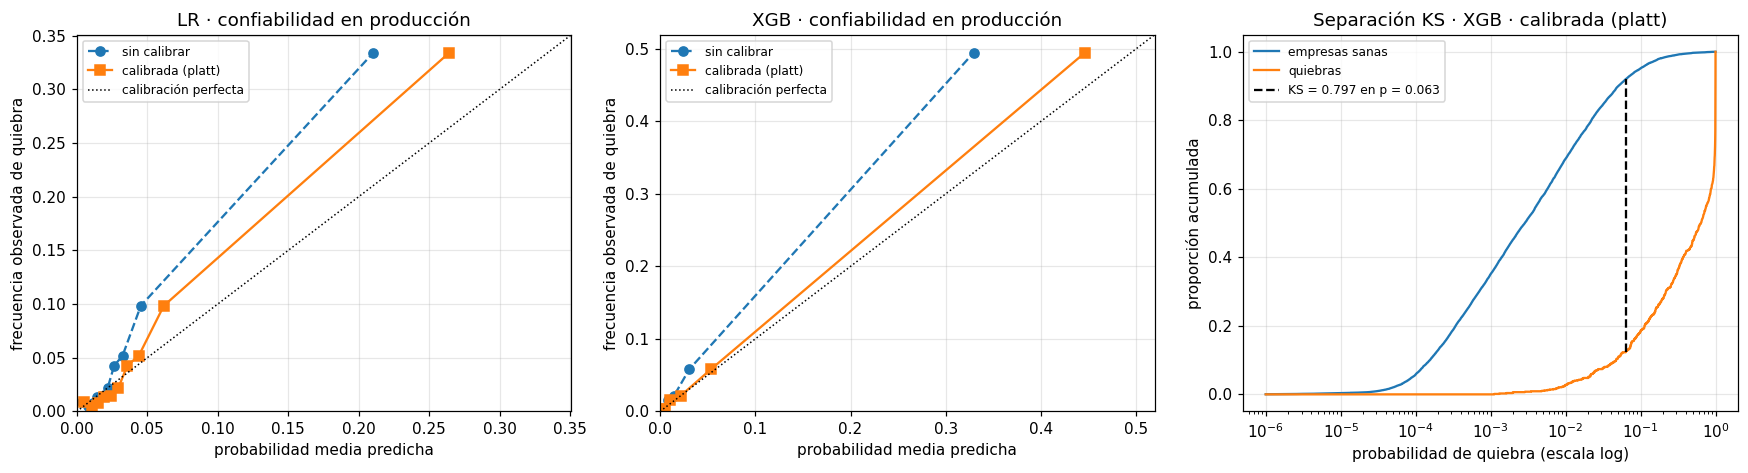

In [24]:
BEST_LABEL = f"{BEST_KIND.upper()} · calibrada ({CAL_METHOD[BEST_KIND]})"
best_p = PROD_PROBS[BEST_LABEL]
rel_rows = []
fig, axes = plt.subplots(1, 3, figsize=(16, 4.4))
for ax, kind in zip(axes[:2], ["lr", "xgb"]):
    lim = 0
    for label, style in [(f"{kind.upper()} · sin calibrar", "o--"), (f"{kind.upper()} · calibrada ({CAL_METHOD[kind]})", "s-")]:
        rt = reliability_table(y_pr, PROD_PROBS[label], n_bins=10, strategy="quantile")
        rel_rows.append(rt.assign(modelo=label))
        ax.plot(rt["p_media"], rt["frecuencia_observada"], style, label=label.split(" · ")[1])
        lim = max(lim, rt["p_media"].max(), rt["frecuencia_observada"].max())
    ax.plot([0, lim * 1.05], [0, lim * 1.05], "k:", lw=1, label="calibración perfecta")
    ax.set_xlim(0, lim * 1.05)
    ax.set_ylim(0, lim * 1.05)
    ax.set_title(f"{kind.upper()} · confiabilidad en producción")
    ax.set_xlabel("probabilidad media predicha")
    ax.set_ylabel("frecuencia observada de quiebra")
    ax.legend(fontsize=8)
s1, s0 = np.sort(best_p[y_pr == 1]), np.sort(best_p[y_pr == 0])
grid_ = np.unique(np.concatenate([s0, s1]))
F1 = np.searchsorted(s1, grid_, side="right") / len(s1)
F0 = np.searchsorted(s0, grid_, side="right") / len(s0)
j = int(np.argmax(np.abs(F0 - F1)))
ax = axes[2]
ax.plot(grid_, F0, label="empresas sanas")
ax.plot(grid_, F1, label="quiebras")
ax.vlines(grid_[j], F1[j], F0[j], colors="k", linestyles="--", label=f"KS = {abs(F0[j] - F1[j]):.3f} en p = {grid_[j]:.3f}")
ax.set_xscale("log")
ax.set_title(f"Separación KS · {BEST_LABEL}")
ax.set_xlabel("probabilidad de quiebra (escala log)")
ax.set_ylabel("proporción acumulada")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()
reliability_bins = pd.concat(rel_rows, ignore_index=True)

### 4.4 Piso de ruido del ECE: ¿qué valor es alcanzable?
Aun un modelo **perfectamente calibrado** muestra ECE > 0 en muestras finitas. Se simula ese piso con la distribución real de probabilidades del modelo recomendado: y ~ Bernoulli(p). Esto contextualiza el criterio del protocolo (ECE ≤ 0.05) según el tamaño de ventana.

In [25]:
rng_nf = np.random.default_rng(SEED)
floor = []
for n_ in [CONFIG["block_size"], 1000, CONFIG["recal_buffer"], len(y_pr)]:
    e = []
    for _ in range(500):
        q = rng_nf.choice(best_p, n_, replace=True)
        e.append(ece_uniform(rng_nf.binomial(1, q), q))
    floor.append({"n": n_, "ECE_esperado_con_calibracion_perfecta": np.mean(e), "p95": np.percentile(e, 95)})
noise_floor = pd.DataFrame(floor)
noise_floor.round(4)

,n,ECE_esperado_con_calibracion_perfecta,p95
0,500,0.0141,0.0216
1,1000,0.0100,0.0149
2,2000,0.0072,0.0107
3,12902,0.0028,0.0041


### 4.5 Umbral de decisión y bandas de riesgo para el dashboard
- **Umbral de alerta:** maximiza F2 (el *recall* pesa el doble: omitir una quiebra cuesta más que una falsa alarma). Se elige con las predicciones fuera de pliegue del split de calibración, no con producción.
- **Bandas de riesgo:** cortes fijos sobre la probabilidad calibrada: Bajo < 5 % ≤ Medio < 20 % ≤ Alto. El 5 % ≈ tasa base y el 20 % ≈ 4× tasa base. Si el modelo está calibrado, la tasa observada en cada banda debe caer dentro de su rango.

In [26]:
def best_fbeta_threshold(y, p, beta):
    grid_t = np.unique(np.quantile(p, np.linspace(0.50, 0.999, 300)))
    scores = [fbeta_score(y, (p >= t).astype(int), beta=beta, zero_division=0) for t in grid_t]
    return float(grid_t[int(np.argmax(scores))])

THRESHOLDS = {k: best_fbeta_threshold(y_ca, OOF[k], CONFIG["fbeta"]) for k in MODELS}
THRESHOLD = THRESHOLDS[BEST_KIND]
yhat = (best_p >= THRESHOLD).astype(int)
print(f"Umbrales F{CONFIG['fbeta']:.0f} (calibración, fuera de pliegue): " + ", ".join(f"{k.upper()} = {v:.4f}" for k, v in THRESHOLDS.items()))
print(f"{BEST_LABEL} en producción → recall {recall_score(y_pr, yhat):.3f} · precisión {precision_score(y_pr, yhat):.3f} · "
      f"F{CONFIG['fbeta']:.0f} {fbeta_score(y_pr, yhat, beta=CONFIG['fbeta']):.3f}")
display(pd.DataFrame(confusion_matrix(y_pr, yhat), index=["real: sana", "real: quiebra"], columns=["pred: sana", "pred: quiebra"]))
cuts = CONFIG["risk_cuts"]
bands = pd.cut(best_p, [0, *cuts, 1.0 + 1e-9], labels=["Bajo", "Medio", "Alto"], right=False, include_lowest=True)
band_tbl = (pd.DataFrame({"banda": bands, "y": y_pr, "p": best_p}).groupby("banda", observed=False)
            .agg(empresas=("y", "size"), quiebras=("y", "sum"), prob_media=("p", "mean"), tasa_observada=("y", "mean")))
band_tbl.round(4)

Umbrales F2 (calibración, fuera de pliegue): LR = 0.0731, XGB = 0.1398
XGB · calibrada (platt) en producción → recall 0.771 · precisión 0.615 · F2 0.734


,pred: sana,pred: quiebra
real: sana,11756,373
real: quiebra,177,596


,empresas,quiebras,prob_media,tasa_observada
banda,,,,
Bajo,10988,82,0.0074,0.0075
Medio,1147,134,0.0975,0.1168
Alto,767,557,0.6595,0.7262


### 4.6 Monitoreo por bloques y políticas de intervención (evaluación prequential)
**En palabras simples:**
- Producción llega en bloques de 500 empresas.
- Antes de puntuar cada bloque, el monitor revisa tres señales.
- La etiqueta real (quiebra o no) de un bloque se conoce **un bloque después**, como en la vida real.
- Cada política decide si interviene usando solo información disponible en ese momento.

**Señales del monitor (umbrales empíricos, no fijos):**

| Señal | Qué compara | Necesita etiquetas | Nivel 1 / Nivel 2 | Rol |
|---|---|---|---|---|
| PSI del score | Scores del bloque vs scores de referencia del modelo | No | percentil 95 / 99 de su distribución nula | **Dispara acciones** |
| z de calibración | (quiebras observadas − esperadas) / √Σp(1−p) en el bloque anterior | Sí, con retraso | percentil 95 / 99 de \|z\| sin drift (predicciones fuera de pliegue) | **Dispara acciones** |
| PSI_máx de variables | Bloque actual vs train (65 variables) | No | percentil 95 / 99 de su distribución nula | Informativa: qué variables cambiaron (vista P3) |

**Diseño de las alertas:**
- El PSI de variables se reporta pero **no dispara intervenciones**.
- Con 65 variables, un cambio estructural persistente mantendría la alarma encendida en todos los bloques aunque no afecte al modelo. Ejemplo: la disponibilidad de `Attr21`, que requiere ventas del año previo, cambia fuertemente entre horizontes.
- Las señales de acción miden lo que importa para la calibración: el score del modelo y el acierto de sus probabilidades.
- Tras cada intervención, la referencia del score pasa a ser el periodo reciente (**acuse de recibo**), para no alertar dos veces por el mismo cambio.
- Los umbrales de \|z\| también son empíricos. Los teóricos (2 / 3) suponen probabilidades exactas fila por fila; con un modelo real el estadístico está sobredisperso y esos umbrales disparan falsas alarmas de más.

**Políticas comparadas (mismos bloques, mismas señales):**
- **Sin calibrar (TT1):** probabilidad cruda del modelo.
- **Baseline calibrado:** calibrador de §4.1, fijo.
- **A · Recalibración:** ante alerta ≥ 1, reajusta Platt con las últimas 2 000 etiquetas disponibles.
- **B · Reentrenamiento:** ante alerta nivel 2 (con enfriamiento de 2 bloques), reentrena con train + etiquetas acumuladas y calibra con las 2 000 más recientes.
- **C · Híbrida:**
  - Recalibra ante alerta.
  - Escala a reentrenamiento si la z de calibración sigue en nivel 2 tras recalibrar.
  - Reentrena por **calendario** cada 10 bloques como frecuencia mínima (protocolo).
- **Oráculo (in-sample):** ajusta Platt con las etiquetas del **mismo** bloque que evalúa (lo que hacía TT1). No es implementable; es una cota superior de referencia.

In [27]:
B_SIZE, L_BUF = CONFIG["block_size"], CONFIG["recal_buffer"]
blocks = [np.arange(s, min(s + B_SIZE, len(idx_pr))) for s in range(0, len(idx_pr), B_SIZE)]
blocks = [b for b in blocks if len(b) >= B_SIZE // 2]
FEAT_THR = psi_null.set_index("n").loc[B_SIZE, ["p95", "p99"]].to_dict()
# Umbrales empíricos de |z|: bloques sin drift del split de calibración con predicciones calibradas FUERA DE PLIEGUE
Z_THR = {k: z_null_thresholds(y_ca, OOF[k], n=B_SIZE, B=500, seed=SEED) for k in MODELS}
print("Umbrales |z| (p95 / p99):", {k.upper(): (round(v["p95"], 2), round(v["p99"], 2)) for k, v in Z_THR.items()}, "· teóricos N(0,1): 1.96 / 2.58")
POLICIES = ["Sin calibrar (TT1)", "Baseline calibrado", "A · Recalibración", "B · Reentrenamiento", "C · Híbrida", "Oráculo (in-sample)"]

def fit_model(kind, X, y):
    if kind == "xgb":
        return XGBClassifier(**XGB_PARAMS, n_estimators=best_iter).fit(X[MODEL_FEATURES], y)
    return make_lr_pipeline(LR_FEATURES, C=best_C, seed=SEED).fit(X, y)

def score_reference(scores, seed):
    """Referencia PSI 1-D de los scores del modelo + umbrales nulos independientes (n = tamaño de bloque)."""
    ref, thr = fit_psi_monitor(pd.DataFrame({"score": scores}), [B_SIZE], B=CONFIG["psi_null_B"], seed=seed, n_bins=CONFIG["psi_bins"])
    return ref, thr[B_SIZE]

def level(v, thr):
    return 2 if v >= thr["p99"] else (1 if v >= thr["p95"] else 0)

def compute_signals(Xb, s_raw, prev, feat_ref, feat_thr, s_ref, s_thr, z_thr):
    fpsi = float(feat_ref.transform(Xb[MODEL_FEATURES]).max())
    spsi = float(s_ref.transform(pd.DataFrame({"score": s_raw})).iloc[0])
    z = np.nan if prev is None else calibration_z(*prev)
    lf, ls = level(fpsi, feat_thr), level(spsi, s_thr)
    lc = 0 if np.isnan(z) else level(abs(z), z_thr)
    # PSI de variables: diagnóstico informativo (no dispara acciones); alerta de acción = score + calibración
    return {"psi_variables_max": fpsi, "psi_score": spsi, "z_calibracion": z, "nivel_variables_info": lf,
            "nivel_score": ls, "nivel_calibracion": lc, "alerta": max(ls, lc)}

def simulate(kind, policy):
    model = MODELS[kind]
    calib = IdentityCalibrator() if policy == "Sin calibrar (TT1)" else CALIBRATOR[kind]
    s_ref, s_thr = score_reference(raw_scores(kind, model, X_ca), SEED)
    pool_X, pool_y = [X_ca], [y_ca]                      # etiquetas disponibles (inicia con calibración)
    last_retrain, last_recal, prev = 0, -10 ** 6, None
    rows, all_y, all_p = [], [], []
    for t, b in enumerate(blocks):
        Xb, yb = X_pr.iloc[b], y_pr[b]
        s_raw = raw_scores(kind, model, Xb)
        sig = compute_signals(Xb, s_raw, prev, psi_train_ref, FEAT_THR, s_ref, s_thr, Z_THR[kind])
        want_retrain = want_recal = calendar = False
        if policy == "A · Recalibración":
            want_recal = sig["alerta"] >= 1 and t > 0
        elif policy == "B · Reentrenamiento":
            want_retrain = sig["alerta"] == 2 and t - last_retrain >= CONFIG["retrain_cooldown"]
        elif policy == "C · Híbrida":
            calendar = t - last_retrain >= CONFIG["calendar_K"]
            escalate = (sig["nivel_calibracion"] == 2 and t - last_recal <= 2
                        and t - last_retrain >= CONFIG["retrain_cooldown"])
            want_retrain = calendar or escalate
            want_recal = (not want_retrain) and sig["alerta"] >= 1 and t > 0
        action, secs = "ninguna", 0.0
        if want_retrain or want_recal:
            t0 = time.perf_counter()
            PX, Py = pd.concat(pool_X), np.concatenate(pool_y)
            if want_retrain:
                model = fit_model(kind, pd.concat([X_tr, PX.iloc[:-L_BUF]]), np.concatenate([y_tr, Py[:-L_BUF]]))
                action, last_retrain = ("reentrenamiento (calendario)" if calendar else "reentrenamiento"), t
            else:
                action, last_recal = "recalibración", t
            s_buf = raw_scores(kind, model, PX.iloc[-L_BUF:])
            calib = PlattScaler().fit(s_buf, Py[-L_BUF:])
            s_ref, s_thr = score_reference(s_buf, SEED + t)   # "acuse de recibo": la referencia pasa a ser el periodo reciente
            secs = time.perf_counter() - t0
            s_raw = raw_scores(kind, model, Xb)
        if policy == "Oráculo (in-sample)" and len(np.unique(yb)) == 2:
            p = PlattScaler().fit(s_raw, yb).predict(s_raw)
        else:
            p = calib.predict(s_raw)
        m = evaluate_probs(yb, p)
        rows.append({"modelo": kind.upper(), "política": policy, "bloque": t,
                     "cohorte_dominante": int(data.loc[idx_pr[b], "cohort"].mode().iloc[0]), **sig,
                     "acción": action, "seg_acción": secs,
                     **{k: m[k] for k in ["n", "positivos", "prevalencia", "p_media", "AUC", "AP", "Brier", "ECE", "LogLoss", "O/E"]}})
        all_y.append(yb)
        all_p.append(p)
        pool_X.append(Xb)
        pool_y.append(yb)
        prev = (yb, p)
    return pd.DataFrame(rows), np.concatenate(all_y), np.concatenate(all_p)

logs, summary_rows = [], []
for kind in MODELS:
    for pol in POLICIES:
        with timed("simulacion_politica", modelo=kind.upper(), politica=pol):
            log, yy, pp = simulate(kind, pol)
        pooled = evaluate_probs(yy, pp)
        logs.append(log)
        summary_rows.append({"modelo": kind.upper(), "política": pol, "AUC": pooled["AUC"], "AP": pooled["AP"],
                             "Brier": pooled["Brier"], "ECE": pooled["ECE"], "LogLoss": pooled["LogLoss"],
                             "ECE_media_por_bloque": log["ECE"].mean(),
                             "recalibraciones": int((log["acción"] == "recalibración").sum()),
                             "reentrenamientos": int(log["acción"].str.startswith("reentrenamiento").sum()),
                             "seg_en_intervenciones": log["seg_acción"].sum(),
                             "%bloques_alerta≥1": 100 * (log["alerta"] >= 1).mean(),
                             "%bloques_alerta=2": 100 * (log["alerta"] == 2).mean()})
policy_blocks = pd.concat(logs, ignore_index=True)
policy_summary = pd.DataFrame(summary_rows)
print(f"{len(blocks)} bloques de {B_SIZE} empresas · buffer de recalibración {L_BUF} · etiquetas con retraso de 1 bloque")
policy_summary.round(4)

Umbrales |z| (p95 / p99): {'LR': (1.97, 2.83), 'XGB': (2.08, 2.68)} · teóricos N(0,1): 1.96 / 2.58
⏱  simulacion_politica: 0.966 s  (RSS 656 MB)
⏱  simulacion_politica: 0.986 s  (RSS 657 MB)
⏱  simulacion_politica: 2.255 s  (RSS 657 MB)
⏱  simulacion_politica: 2.538 s  (RSS 663 MB)
⏱  simulacion_politica: 3.807 s  (RSS 665 MB)
⏱  simulacion_politica: 1.064 s  (RSS 665 MB)
⏱  simulacion_politica: 1.603 s  (RSS 665 MB)
⏱  simulacion_politica: 1.459 s  (RSS 665 MB)
⏱  simulacion_politica: 3.658 s  (RSS 665 MB)
⏱  simulacion_politica: 20.302 s  (RSS 669 MB)
⏱  simulacion_politica: 22.774 s  (RSS 669 MB)
⏱  simulacion_politica: 1.781 s  (RSS 669 MB)
26 bloques de 500 empresas · buffer de recalibración 2000 · etiquetas con retraso de 1 bloque


,modelo,política,AUC,AP,Brier,ECE,LogLoss,ECE_media_por_bloque,recalibraciones,reentrenamientos,seg_en_intervenciones,%bloques_alerta≥1,%bloques_alerta=2
0,LR,Sin calibrar (TT1),0.8554,0.4207,0.0456,0.0217,0.1744,0.0264,0,0,0.0000,69.2308,34.6154
1,LR,Baseline calibrado,0.8554,0.4207,0.0445,0.0118,0.1692,0.0209,0,0,0.0000,23.0769,7.6923
2,LR,A · Recalibración,0.8545,0.4215,0.0445,0.0112,0.1683,0.0218,3,0,0.5390,11.5385,7.6923
3,LR,B · Reentrenamiento,0.8612,0.4406,0.0434,0.0083,0.1645,0.0211,0,1,0.9385,23.0769,3.8462
4,LR,C · Híbrida,0.8639,0.4428,0.0432,0.0083,0.1631,0.0220,3,3,2.8232,15.3846,7.6923
5,LR,Oráculo (in-sample),0.8584,0.4361,0.0436,0.0072,0.1653,0.0166,0,0,0.0000,0.0000,0.0000
6,XGB,Sin calibrar (TT1),0.9636,0.8025,0.0275,0.0206,0.1007,0.0223,0,0,0.0000,84.6154,76.9231
7,XGB,Baseline calibrado,0.9636,0.8025,0.0236,0.0059,0.0878,0.0164,0,0,0.0000,23.0769,15.3846
8,XGB,A · Recalibración,0.9631,0.8054,0.0230,0.0031,0.0866,0.0157,3,0,0.7949,11.5385,0.0000
9,XGB,B · Reentrenamiento,0.9707,0.8340,0.0210,0.0032,0.0782,0.0146,0,2,18.5791,19.2308,7.6923


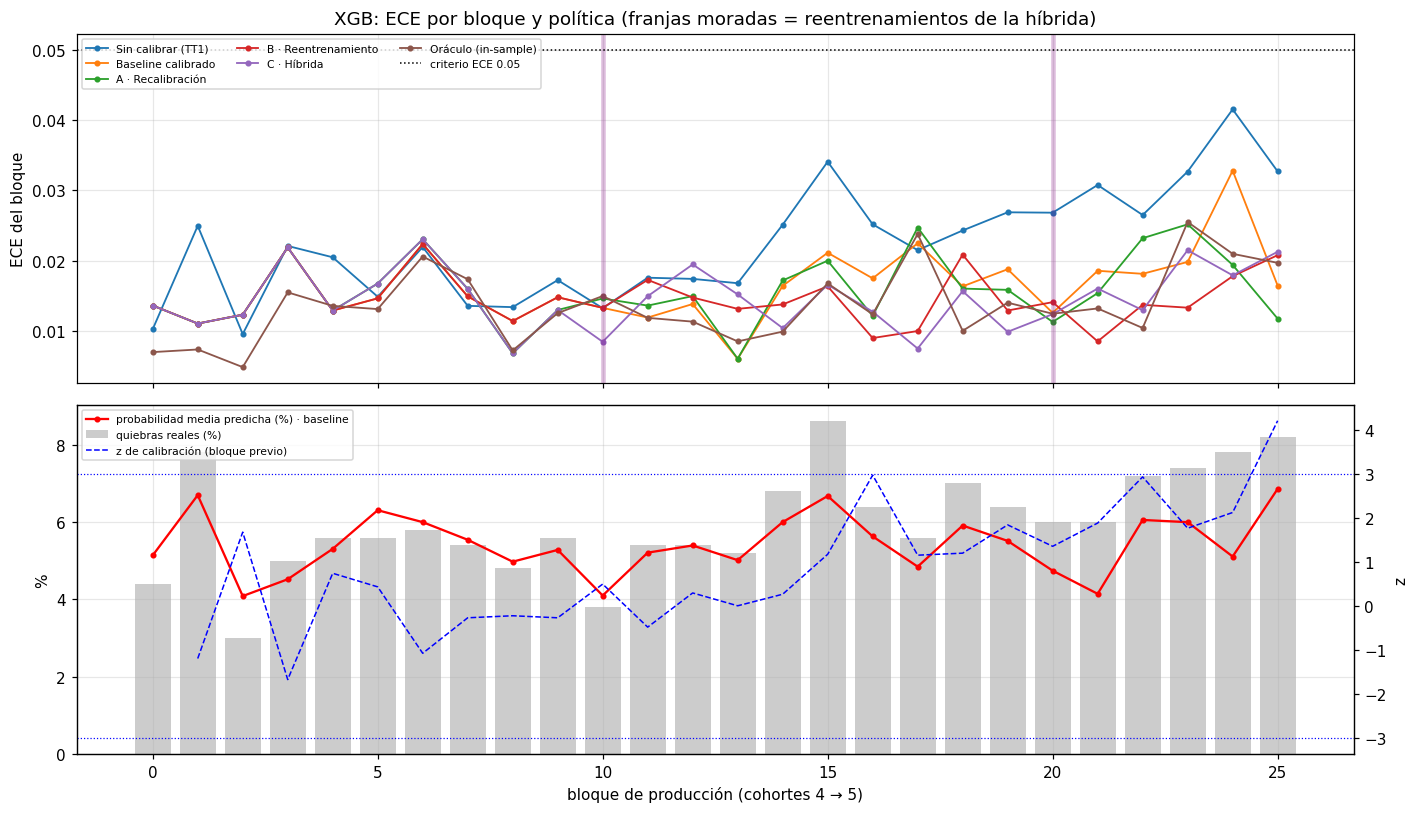

In [28]:
sub = policy_blocks[policy_blocks["modelo"] == BEST_KIND.upper()]
fig, axes = plt.subplots(2, 1, figsize=(13, 7.5), sharex=True)
for pol, g in sub.groupby("política", sort=False):
    axes[0].plot(g["bloque"], g["ECE"], marker=".", lw=1.2, label=pol)
hyb = sub[(sub["política"] == "C · Híbrida") & sub["acción"].str.startswith("reentrenamiento")]
for x in hyb["bloque"]:
    axes[0].axvline(x, color="purple", alpha=0.25, lw=3)
axes[0].axhline(0.05, color="k", ls=":", lw=1, label="criterio ECE 0.05")
axes[0].set_ylabel("ECE del bloque")
axes[0].set_title(f"{BEST_KIND.upper()}: ECE por bloque y política (franjas moradas = reentrenamientos de la híbrida)")
axes[0].legend(fontsize=7, ncol=3)
base = sub[sub["política"] == "Baseline calibrado"]
axes[1].bar(base["bloque"], 100 * base["prevalencia"], color="#cccccc", label="quiebras reales (%)")
axes[1].plot(base["bloque"], 100 * base["p_media"], "r.-", label="probabilidad media predicha (%) · baseline")
axes[1].set_ylabel("%")
axes[1].set_xlabel("bloque de producción (cohortes 4 → 5)")
ax2 = axes[1].twinx()
ax2.plot(base["bloque"], base["z_calibracion"], "b--", lw=1, label="z de calibración (bloque previo)")
for h in (-3, 3):
    ax2.axhline(h, color="b", ls=":", lw=0.8)
ax2.set_ylabel("z")
ax2.grid(False)
h1, l1 = axes[1].get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
axes[1].legend(h1 + h2, l1 + l2, fontsize=7, loc="upper left")
plt.tight_layout()
plt.show()

**Lectura de las políticas (ver tabla y figura):**
- **Calibrar en el despliegue es la primera intervención.** Sin calibración (TT1) el monitor detecta miscalibración en la mayoría de los bloques; con el baseline calibrado las alertas caen a una minoría.
- **XGBoost:**
  - Las tres políticas activas reducen el ECE agregado respecto del baseline calibrado (≈ 0.006 → ≈ 0.003).
  - La híbrida logra el menor ECE y, junto con reentrenamiento, el mayor AUC/AP: reentrenar incorpora la relación ratios→quiebra de los horizontes cercanos.
- **Costo:**
  - Recalibrar cuesta décimas de segundo en total.
  - B y C gastan ~10 s en 2 reentrenamientos; la híbrida obtiene mejor calibración que B con un costo similar.
- **Oráculo:** la híbrida iguala su ECE agregado sin usar las etiquetas del bloque evaluado. El "éxito" de la recalibración in-sample de TT1 era alcanzable, pero solo con un protocolo que no filtra información.
- **Escala por bloque:** el ECE por bloque (≈ 0.015) está cerca del piso de ruido para 500 empresas (§4.4). A esa escala las políticas son casi indistinguibles; la diferencia real se ve en el ECE agregado y en AUC/AP.

### 4.7 Validación del monitor: falsas alarmas y latencia (criterios del protocolo)
En TT1 estos criterios quedaron como "N/A" porque no había periodos sin drift ni un inicio de drift conocido. Aquí se construyen escenarios de **verdad conocida** con los datos reales.

**Construcción de los escenarios:**
- Producción se divide al azar en dos mitades.
- Con la primera se "despliega" un sistema calibrado para esa distribución: calibrador Platt, referencias PSI y umbrales nulos.
- Con la segunda se generan flujos de 20 bloques:
  - **Estacionario**, sin cambio: toda alerta es falsa → tasa de falsas alarmas por bloque.
  - **Label shift inyectado** desde el bloque 11: la tasa de quiebra se multiplica × *m* (1.5, 2, 3) → latencia en empresas observadas desde el inicio del cambio hasta la primera alerta.

Criterios del protocolo: falsas alarmas < 15 % y latencia ≤ 500 muestras bajo drift moderado.

In [29]:
def monitor_validation(kind, R, multipliers, n_pre=10, n_post=10, seed=SEED):
    rng = np.random.default_rng(seed)
    model = MODELS[kind]
    perm = rng.permutation(len(idx_pr))
    h_ref, h_str = perm[: len(perm) // 2], perm[len(perm) // 2:]
    s_all = raw_scores(kind, model, X_pr)
    cal_v = PlattScaler().fit(s_all[h_ref], y_pr[h_ref])
    oof_v = np.zeros(len(h_ref))                                  # Platt fuera de pliegue (2 pliegues) para umbrales de |z|
    for a, b in [(slice(None, len(h_ref) // 2), slice(len(h_ref) // 2, None)), (slice(len(h_ref) // 2, None), slice(None, len(h_ref) // 2))]:
        oof_v[b] = PlattScaler().fit(s_all[h_ref][a], y_pr[h_ref][a]).predict(s_all[h_ref][b])
    z_thr = z_null_thresholds(y_pr[h_ref], oof_v, n=B_SIZE, B=500, seed=seed)
    f_ref, f_thr = fit_psi_monitor(X_pr.iloc[h_ref][MODEL_FEATURES], [B_SIZE], B=CONFIG["psi_null_B"], seed=seed, n_bins=CONFIG["psi_bins"])
    f_thr = f_thr[B_SIZE]
    s_ref, s_thr = score_reference(s_all[h_ref], seed)
    pos, neg = h_str[y_pr[h_str] == 1], h_str[y_pr[h_str] == 0]
    pi = len(pos) / len(h_str)
    far_rows, lat_rows = [], []
    for m in [1.0] + list(multipliers):
        for _ in range(R):
            prev, first = None, {1: None, 2: None}
            for t in range(n_pre + n_post):
                mult = 1.0 if t < n_pre else m
                k = rng.binomial(B_SIZE, min(pi * mult, 0.95))
                ib = np.concatenate([rng.choice(pos, k, replace=True), rng.choice(neg, B_SIZE - k, replace=True)])
                sig = compute_signals(X_pr.iloc[ib], s_all[ib], prev, f_ref, f_thr, s_ref, s_thr, z_thr)
                prev = (y_pr[ib], cal_v.predict(s_all[ib]))
                if t < n_pre or m == 1.0:
                    if t >= 1:
                        far_rows.append({k: sig[k] for k in ["alerta", "nivel_score", "nivel_calibracion", "nivel_variables_info"]})
                else:
                    for lv in (1, 2):
                        if first[lv] is None and sig["alerta"] >= lv:
                            first[lv] = (t - n_pre + 1) * B_SIZE
            if m != 1.0:
                lat_rows.append({"multiplicador_de_prevalencia": m, "latencia_N1": first[1], "latencia_N2": first[2]})
    far = pd.DataFrame(far_rows)
    far_tbl = pd.DataFrame([{"señal": name, "bloques_sin_drift": len(far), "falsas_alarmas_nivel≥1_%": 100 * (far[col] >= 1).mean(),
                             "falsas_alarmas_nivel2_%": 100 * (far[col] == 2).mean()}
                            for name, col in [("ALERTA DE ACCIÓN (score + calibración)", "alerta"), ("PSI del score", "nivel_score"),
                                              ("z de calibración", "nivel_calibracion"), ("PSI de variables (informativa)", "nivel_variables_info")]])
    lat = pd.DataFrame(lat_rows).astype(float)
    lat_tbl = lat.groupby("multiplicador_de_prevalencia").agg(
        deteccion_N2_=("latencia_N2", lambda s: 100 * s.notna().mean()),
        latencia_mediana_N2=("latencia_N2", "median"),
        deteccion_N1_=("latencia_N1", lambda s: 100 * s.notna().mean()),
        latencia_mediana_N1=("latencia_N1", "median")).rename(columns={"deteccion_N2_": "detección_N2_%", "deteccion_N1_": "detección_N1_%"})
    return far_tbl, lat_tbl

with timed("validacion_monitor_falsas_alarmas_latencia", modelo=BEST_KIND.upper()):
    far_tbl, lat_tbl = monitor_validation(BEST_KIND, CONFIG["monitor_validation_R"], CONFIG["latency_multipliers"])
print("Tasa de falsas alarmas por bloque en flujos sin drift:")
display(far_tbl.round(2))
print("Latencia (empresas observadas desde el inicio del cambio hasta la alerta) y tasa de detección en 10 bloques:")
lat_tbl.round(1)

⏱  validacion_monitor_falsas_alarmas_latencia: 21.947 s  (RSS 670 MB)
Tasa de falsas alarmas por bloque en flujos sin drift:


,señal,bloques_sin_drift,falsas_alarmas_nivel≥1_%,falsas_alarmas_nivel2_%
0,ALERTA DE ACCIÓN (score + calibración),920,17.61,8.15
1,PSI del score,920,4.78,3.04
2,z de calibración,920,13.91,5.33
3,PSI de variables (informativa),920,3.91,0.98


Latencia (empresas observadas desde el inicio del cambio hasta la alerta) y tasa de detección en 10 bloques:


,detección_N2_%,latencia_mediana_N2,detección_N1_%,latencia_mediana_N1
multiplicador_de_prevalencia,,,,
1.5,100.0,1000.0,100.0,1000.0
2.0,100.0,1000.0,100.0,500.0
3.0,100.0,500.0,100.0,500.0


**Lectura frente a los criterios del protocolo:**
- **Falsas alarmas:**
  - La alerta de **nivel 2**, que dispara reentrenamientos, se mantiene por debajo de 15 % → **cumple**.
  - La de nivel 1, que solo recalibra (costo de décimas de segundo), queda cerca del límite. La aporta sobre todo la z de calibración, sensible a pequeñas diferencias entre el periodo de referencia y el flujo.
  - Si se quiere bajarla, basta exigir dos bloques consecutivos (persistencia) a cambio de un bloque más de latencia.
- **Latencia:**
  - Con la prevalencia ×2 o ×3, la alerta de nivel 1 llega en el primer bloque tras el cambio (500 empresas) → **cumple ≤ 500**.
  - Con un cambio leve (×1.5) tarda ≈ 1 000.
- **Complementariedad:** el PSI del score detecta cambios sin esperar etiquetas; la z de calibración confirma, con etiquetas, si las probabilidades dejaron de ser correctas. Por eso ambas señales disparan acciones.

### 4.8 Comparación TT1 vs TT2
Las cifras de TT1 provienen del reporte técnico. **Advertencia:** en TT1 el split de calibración tenía 11.4 % de quiebras por el orden artificial de las filas, y las métricas de producción promediaban ventanas mayoritariamente sin quiebras. La comparación muestra la magnitud del cambio, pero **las cifras TT2 son las únicas metodológicamente válidas**.

In [30]:
tt1 = pd.DataFrame([
    {"comparación": "LR · split de calibración, sin calibrar", "AUC": 0.7611, "AP": 0.2663, "ECE": 0.2807, "Brier": 0.1898},
    {"comparación": "XGB · split de calibración, sin calibrar", "AUC": 0.9425, "AP": 0.8232, "ECE": 0.0301, "Brier": 0.0442},
    {"comparación": "XGB · producción · Baseline", "AUC": 0.9172, "AP": np.nan, "ECE": 0.0416, "Brier": 0.0250},
    {"comparación": "XGB · producción · mejor política activa", "AUC": 0.9172, "AP": np.nan, "ECE": 0.0620, "Brier": 0.0245},
]).assign(fuente="TT1")

def mrow(label, y, p):
    m = evaluate_probs(y, p)
    return {"comparación": label, "AUC": m["AUC"], "AP": m["AP"], "ECE": m["ECE"], "Brier": m["Brier"]}

xgb_pol = policy_summary[policy_summary["modelo"] == "XGB"].set_index("política")
best_active = xgb_pol.loc[["A · Recalibración", "B · Reentrenamiento", "C · Híbrida"], "ECE"].idxmin()
tt2 = pd.DataFrame([
    mrow("LR · split de calibración, sin calibrar", y_ca, raw_cal["lr"]),
    mrow("XGB · split de calibración, sin calibrar", y_ca, raw_cal["xgb"]),
    {"comparación": "XGB · producción · Baseline", **xgb_pol.loc["Baseline calibrado", ["AUC", "AP", "ECE", "Brier"]].to_dict()},
    {"comparación": "XGB · producción · mejor política activa", **xgb_pol.loc[best_active, ["AUC", "AP", "ECE", "Brier"]].to_dict()},
]).assign(fuente="TT2")
comparison = pd.concat([tt1, tt2], ignore_index=True)
print(f"Mejor política activa TT2 (XGB, menor ECE en producción): {best_active}")
comparison.pivot_table(index="comparación", columns="fuente", values=["AUC", "AP", "ECE", "Brier"]).round(4)

Mejor política activa TT2 (XGB, menor ECE en producción): C · Híbrida


AP             AUC           Brier             ECE        
fuente                                       TT1     TT2     TT1     TT2     TT1     TT2     TT1     TT2
comparación                                                                                             
LR · split de calibración, sin calibrar   0.2663  0.3602  0.7611  0.8463  0.1898  0.0420  0.2807  0.0148
XGB · producción · Baseline                  NaN  0.8025  0.9172  0.9636  0.0250  0.0236  0.0416  0.0059
XGB · producción · mejor política activa     NaN  0.8316  0.9172  0.9702  0.0245  0.0210  0.0620  0.0026
XGB · split de calibración, sin calibrar  0.8232  0.7667  0.9425  0.9588  0.0442  0.0247  0.0301  0.0153

## 5. Preparación para el dashboard (pipeline de inferencia)
### 5.1 Empaquetado del modelo y exportación de artefactos
**`bundle.joblib`** es un único objeto que el dashboard carga. Contiene:
- Los dos `BankruptcyScorer` (modelo + preprocesamiento + calibrador + umbral + bandas).
- El modelo recomendado.
- La referencia PSI de train y sus umbrales nulos.
- El diccionario de variables.

**Otros archivos:**
- El modelo XGBoost también se guarda en formato nativo `.json`, portable entre versiones.
- Se copia `polish_tt2.py` junto a los artefactos.
- `metadata.json` documenta la corrida: configuración, entorno, hashes de datos, métricas y tiempos.
- Cada tabla del análisis se exporta en parquet (o CSV) para las vistas del dashboard.

In [31]:
scorers = {k: BankruptcyScorer(name=f"{k.upper()} + {CAL_METHOD[k]}", kind=k, model=MODELS[k], calibrator=CALIBRATOR[k],
                               threshold=THRESHOLDS[k], risk_cuts=CONFIG["risk_cuts"]) for k in MODELS}
bundle = {"schema_version": "1.0", "run_id": RUN_ID, "created_utc": dt.datetime.now(dt.timezone.utc).isoformat(),
          "dataset": "Polish Companies Bankruptcy (UCI 365)", "scorers": scorers, "best": BEST_KIND,
          "psi_reference": psi_train_ref, "psi_null": psi_null.set_index("n")[["p95", "p99"]].to_dict(orient="index"),
          "feature_labels": FEATURE_LABELS, "model_features": MODEL_FEATURES, "lr_features": LR_FEATURES}

def _cal_params(c):
    return {a.rstrip("_"): float(getattr(c, a)) for a in ("T_", "a_", "b_") if hasattr(c, a)}

best_row = metrics_production.set_index("modelo").loc[BEST_LABEL]
metadata = {
    "schema_version": "1.0", "run_id": RUN_ID, "proyecto": "TT 2026-B080 · Detección y Mitigación de Calibration Drift",
    "dataset": "Polish Companies Bankruptcy (UCI 365)", "entorno": ENV, "config": CONFIG, "sha256_datos": DATA_HASHES,
    "correccion_orden": fix_info,
    "particion": {s: {"filas": int(len(y)), "prevalencia": float(y.mean())} for s, y in [("train", y_tr), ("calibration", y_ca), ("production", y_pr)]},
    "modelos": {k: {"calibrador": CAL_METHOD[k], "parametros_calibrador": _cal_params(CALIBRATOR[k]), "umbral_F2": THRESHOLDS[k]} for k in MODELS},
    "xgb_n_arboles": best_iter, "lr_C": best_C, "lr_variables": LR_FEATURES, "modelo_recomendado": BEST_KIND,
    "metricas_produccion_modelo_recomendado": best_row.to_dict(),
    "bandas_riesgo": {"Bajo": f"< {CONFIG['risk_cuts'][0]}", "Medio": f"{CONFIG['risk_cuts'][0]}–{CONFIG['risk_cuts'][1]}", "Alto": f"≥ {CONFIG['risk_cuts'][1]}"},
}
tables = {"entorno": pd.DataFrame([ENV]), "reporte_carga": load_report, "diagnostico_orden": pd.DataFrame(order_diag),
          "validacion_dataset": validation, "particion": split_summary, "faltantes_top": miss_tbl.reset_index(names="variable"),
          "grupos_colinealidad": cl, "psi_cohortes": psi_cohorts.reset_index(names="variable"),
          "psi_splits": psi_splits.reset_index(names="variable"), "psi_umbrales_nulos": psi_null,
          "seleccion_C_lr": lr_search, "tiempos_protocolo": timing_protocol, "ablaciones": ablation, "benchmark": benchmark,
          "seleccion_calibrador": calib_sel, "metricas_produccion": metrics_production, "confiabilidad_bins": reliability_bins,
          "piso_ruido_ece": noise_floor, "bandas_riesgo": band_tbl.reset_index().astype({"banda": str}),
          "politicas_bloques": policy_blocks, "politicas_resumen": policy_summary,
          "monitor_falsas_alarmas": far_tbl, "monitor_latencia": lat_tbl.reset_index(), "tt1_vs_tt2": comparison}
with timed("exportacion_artefactos"):
    joblib.dump(bundle, ART / "bundle.joblib", compress=3)
    xgb_model.save_model(ART / "xgb_model.json")
    shutil.copy("src/polish_tt2.py", ART / "polish_tt2.py")
    saved = {name: save_table(df, name).name for name, df in tables.items() if isinstance(df, pd.DataFrame) and len(df)}
    metadata["artefactos"] = ["bundle.joblib", "xgb_model.json", "polish_tt2.py", "metadata.json", *saved.values()]
    (ART / "metadata.json").write_text(json.dumps(metadata, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
print(f"Artefactos en {ART.resolve()}")
pd.DataFrame({"archivo": sorted(p.name for p in ART.iterdir())})

⏱  exportacion_artefactos: 0.205 s  (RSS 677 MB)
Artefactos en /content/artifacts/bankruptcy/tt2_polish_20261018T143258Z


,archivo
0,ablaciones.parquet
1,bandas_riesgo.parquet
2,benchmark.parquet
3,bundle.joblib
4,confiabilidad_bins.parquet
5,diagnostico_orden.parquet
6,entorno.parquet
7,faltantes_top.parquet
8,grupos_colinealidad.parquet
9,metadata.json


### 5.2 Función de inferencia `predict_bankruptcy(nuevos_datos)`
Simula cómo el dashboard consumirá el modelo:
1. Carga el bundle **desde disco**, con caché.
2. Acepta un `dict` (formulario), una lista de dicts, un `DataFrame` (archivo subido) o un arreglo NumPy.
3. Tolera ratios ausentes (los trata como faltantes) y avisa de columnas desconocidas.
4. Devuelve por empresa:
   - Probabilidad calibrada.
   - Banda de riesgo.
   - Alerta según el umbral F2.
   - Número de faltantes.
   - Los factores que más empujan la predicción (SHAP nativo de XGBoost o coeficiente × valor en la LR).
5. Con lotes de ≥ 200 empresas añade un **reporte de drift** (PSI contra train con umbrales empíricos) en `resultado.attrs["drift"]`.

In [32]:
_BUNDLES = {}

def load_bundle(path=ART / "bundle.joblib"):
    path = Path(path).resolve()
    if path not in _BUNDLES:
        _BUNDLES[path] = joblib.load(path)
    return _BUNDLES[path]

def predict_bankruptcy(nuevos_datos, modelo="best", bundle_path=ART / "bundle.joblib", explicar=True, top_k=3, verificar_drift=True):
    """Predicción calibrada de quiebra para el dashboard.

    nuevos_datos : dict | list[dict] | pandas.DataFrame | numpy.ndarray con columnas Attr1…Attr64
    modelo       : "best" (recomendado), "xgb" o "lr"
    Devuelve un DataFrame con prob_quiebra, banda_riesgo, alerta, n_faltantes y factores_principales;
    en .attrs["drift"] el reporte de drift del lote (si tiene ≥ 200 filas) y en .attrs["modelo"] el modelo usado.
    """
    if isinstance(nuevos_datos, dict):
        df = pd.DataFrame([nuevos_datos])
    elif isinstance(nuevos_datos, (list, tuple)):
        df = pd.DataFrame(list(nuevos_datos))
    elif isinstance(nuevos_datos, np.ndarray):
        arr = np.atleast_2d(nuevos_datos)
        df = pd.DataFrame(arr, columns=RAW_FEATURES[: arr.shape[1]])
    elif isinstance(nuevos_datos, pd.DataFrame):
        df = nuevos_datos.copy()
    else:
        raise TypeError("nuevos_datos debe ser dict, lista de dicts, DataFrame o ndarray")
    res = polish_tt2.score_batch(load_bundle(bundle_path), df, model=modelo, explain=explicar, top_k=top_k, drift_check=verificar_drift)
    for w in res["advertencias"]:
        print("⚠️ ", w)
    out = res["predicciones"]
    out.attrs["modelo"], out.attrs["drift"] = res["modelo"], res["drift"]
    return out

### 5.3 Prueba de consumo (simulación del dashboard)
Se ejercitan los tres usos que tendrá la interfaz:
1. Tabla de empresas.
2. Formulario parcial con un campo inválido.
3. Lote grande con verificación de drift.

Además se comprueba que las probabilidades del bundle cargado desde disco coinciden con las del notebook.

El formulario parcial ilustra por qué el dashboard debe mostrar `n_faltantes` y exigir un mínimo de ratios: con 60 de 64 faltantes la probabilidad no es confiable.

In [33]:
with timed("prueba_inferencia_dashboard"):
    _BUNDLES.clear()
    muestra = data.loc[idx_pr[:5], RAW_FEATURES]
    pred = predict_bankruptcy(muestra)
p_nb = CALIBRATOR[BEST_KIND].predict(raw_scores(BEST_KIND, MODELS[BEST_KIND], X_all.loc[idx_pr[:5]]))
print(f"Modelo usado: {pred.attrs['modelo']} · consistencia bundle (disco) ↔ notebook: {np.allclose(pred['prob_quiebra'].to_numpy(), p_nb)}")
display(pred.assign(real=data.loc[idx_pr[:5], "class"].to_numpy()))

print("\nFormulario parcial (4 ratios + un campo inválido):")
display(predict_bankruptcy({"Attr1": 0.05, "Attr2": 0.60, "Attr27": 1.2, "Attr46": 0.9, "campo_invalido": 3}, verificar_drift=False))

with timed("inferencia_lote_1000_con_drift"):
    lote = predict_bankruptcy(data.loc[idx_pr[-1000:], RAW_FEATURES], explicar=False)
print("Reporte de drift del lote:")
print(json.dumps(lote.attrs["drift"], ensure_ascii=False, indent=1))
lote["banda_riesgo"].value_counts()

⚠️  Verificación de drift omitida: se requieren ≥ 200 filas
⏱  prueba_inferencia_dashboard: 0.065 s  (RSS 678 MB)
Modelo usado: xgb · consistencia bundle (disco) ↔ notebook: True


,prob_quiebra,banda_riesgo,alerta,n_faltantes,factores_principales,real
30102,0.009112,Bajo,0,1,Attr33 ↓ (Gastos operativos / pasivos a corto ...,0
30103,0.005445,Bajo,0,5,Attr5 ↓ ([(Efectivo + valores CP + cuentas por...,0
30104,0.000785,Bajo,0,1,Attr5 ↓ ([(Efectivo + valores CP + cuentas por...,0
30105,0.006685,Bajo,0,1,Attr27 ↓ (Utilidad de operación / gastos finan...,0
30106,0.007892,Bajo,0,0,Attr58 ↓ (Costos totales / ventas totales); At...,0



Formulario parcial (4 ratios + un campo inválido):
⚠️  Columnas ignoradas (no son Attr1–Attr64): ['campo_invalido']
⚠️  60 de 64 ratios ausentes → se tratan como faltantes (NaN)


,prob_quiebra,banda_riesgo,alerta,n_faltantes,factores_principales
0,0.000003,Bajo,0,60,Attr5 ↓ ([(Efectivo + valores CP + cuentas por...


⏱  inferencia_lote_1000_con_drift: 0.060 s  (RSS 678 MB)
Reporte de drift del lote:
{
 "n": 1000,
 "psi_max": 0.6085588468373203,
 "nivel": 2,
 "umbral_p95": 0.03474222737691375,
 "umbral_p99": 0.03906800752721585,
 "n_referencia_umbral": 1000,
 "top_variables": {
  "Attr21": 0.6086,
  "Attr43": 0.0759,
  "Attr55": 0.0611,
  "Attr44": 0.0594,
  "Attr29": 0.0576
 }
}


,count
banda_riesgo,
Bajo,848
Medio,87
Alto,65


### 5.4 Contrato de artefactos → vistas del dashboard (observación 5)
El maquetado visual es un entregable aparte. Esta tabla fija **qué datos alimentan cada vista**, de modo que el frontend no calcula nada y solo lee artefactos versionados por `run_id`.

| Vista del dashboard | Artefactos |
|---|---|
| P1 · Resumen ejecutivo (semáforo vs criterios del protocolo) | `metadata.json`, `metricas_produccion`, `politicas_resumen`, `monitor_falsas_alarmas`, `monitor_latencia` |
| P2 · Dataset (ficha llana, validador, EDA) | `reporte_carga`, `diagnostico_orden`, `validacion_dataset`, `particion`, `faltantes_top`, `psi_cohortes` |
| P3 · Monitor temporal (señales y alertas por bloque) | `politicas_bloques` (señales, niveles, acciones), `psi_umbrales_nulos` |
| P4 · Comparación de políticas (tabla, curvas, costo) | `politicas_resumen`, `politicas_bloques`, `tt1_vs_tt2` |
| P5 · Calibración (confiabilidad, piso de ruido, bandas) | `confiabilidad_bins`, `seleccion_calibrador`, `piso_ruido_ece`, `bandas_riesgo` |
| P6 · Predicción interactiva (*what-if*) | `bundle.joblib` + `polish_tt2.py` → `polish_tt2.score_batch()` |
| P7 · Rendimiento computacional | `tiempos_protocolo`, `tiempos_etapas`, `entorno` |
| P8 · Reproducibilidad | `metadata.json` (config, semillas, versiones, SHA-256 de datos) |

Consumo mínimo desde el dashboard:
```python
import sys, joblib; sys.path.insert(0, "<carpeta_de_artefactos>")
import polish_tt2
bundle = joblib.load("<carpeta_de_artefactos>/bundle.joblib")
resultado = polish_tt2.score_batch(bundle, df_empresas)
```

### 5.5 Resumen de tiempos de procesamiento y empaquetado final (observación 1)

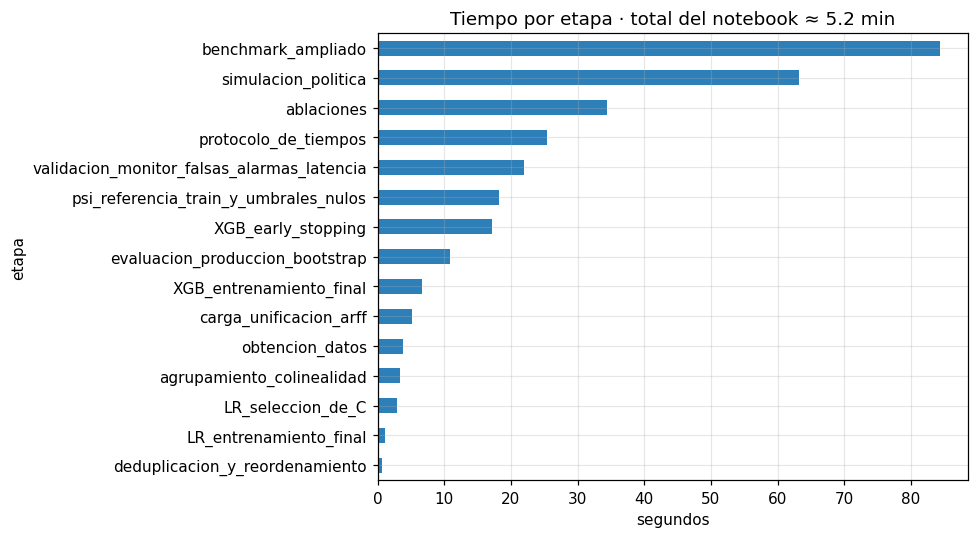

Tiempo total de ejecución: 313.4 s en 2 CPU lógicos. RNF-03 (≤ 90 min para los tres datasets ≈ 30 min por dataset): ✅ cumple
Paquete de artefactos: /content/artifacts/bankruptcy/tt2_polish_20261018T143258Z.zip


,segundos
etapa,
benchmark_ampliado,84.354
simulacion_politica,63.194
ablaciones,34.438
protocolo_de_tiempos,25.453
validacion_monitor_falsas_alarmas_latencia,21.947
psi_referencia_train_y_umbrales_nulos,18.240
XGB_early_stopping,17.207
evaluacion_produccion_bootstrap,10.914
XGB_entrenamiento_final,6.705


In [34]:
timings_df = pd.DataFrame(TIMINGS)
save_table(timings_df, "tiempos_etapas")
total = time.perf_counter() - NOTEBOOK_T0
agg = timings_df.groupby("etapa", sort=False)["segundos"].sum().sort_values(ascending=False)
ax = agg.head(15).iloc[::-1].plot(kind="barh", figsize=(9, 5), color="#2c7fb8",
                                    title=f"Tiempo por etapa · total del notebook ≈ {total / 60:.1f} min")
ax.set_xlabel("segundos")
plt.tight_layout()
plt.show()
print(f"Tiempo total de ejecución: {total:,.1f} s en {ENV['cpus_logicos']} CPU lógicos. "
      f"RNF-03 (≤ 90 min para los tres datasets ≈ 30 min por dataset): {'✅ cumple' if total < 30 * 60 else '⚠️ revisar'}")
zip_path = shutil.make_archive(str(ART), "zip", ART)
print(f"Paquete de artefactos: {zip_path}")
if IN_COLAB and CONFIG["download_artifacts"]:
    from google.colab import files
    files.download(zip_path)
agg.round(3).to_frame("segundos")

### Cierre: observaciones del jurado resueltas en este notebook
| # | Observación | Evidencia en el notebook |
|---|---|---|
| 1 | Tiempos de procesamiento | `%%time` en entrenamientos; registro `TIMINGS` por etapa con memoria; protocolo con repeticiones y hardware (§3.5); resumen y exportación (§5.5); costo en segundos de cada intervención (§4.6). |
| 2 | Justificación de modelos | Argumentación técnica (§3.1); ablaciones (§3.6); benchmark de 5 candidatos con desempeño, calibración y tiempo (§3.7). |
| 3 | Explicación sin tecnicismos | Ficha en lenguaje llano (§1.5), reutilizable en la vista P2 del dashboard. |
| 4 | Requisitos de dataset candidato | `validate_dataset()` con 10 requisitos medibles; detecta el defecto de orden que invalidó TT1 (§1.7). |
| 5 | Maquetado del dashboard | Contrato de artefactos por vista y función de inferencia probada (§5.1–5.4). |
| 6 | Estático vs ajuste de dimensionalidad | Postura explícita y agrupamiento de colinealidad ajustado solo en train (§2.5); ablación de dimensionalidad (§3.6). |